# Detekcja Phishingu - Random Forest

Ten notebook zawiera implementację i analizę modelu Random Forest do wykrywania phishingu.

## 1. Import bibliotek i konfiguracja


In [1]:
from pathlib import Path
import os
import sys

start_dir = Path.cwd().resolve()
backend_root = None
for candidate in (start_dir, *start_dir.parents):
    if (candidate / 'utils').is_dir() and (candidate / 'notebooks').is_dir():
        backend_root = candidate
        break
    nested_backend = candidate / 'backend'
    if (nested_backend / 'utils').is_dir() and (nested_backend / 'notebooks').is_dir():
        backend_root = nested_backend
        break

if backend_root is None:
    raise RuntimeError(
        f'Cannot locate backend root from Jupyter working directory: {start_dir}'
    )

notebooks_dir = backend_root / 'notebooks'
os.chdir(notebooks_dir)
if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import pickle

import importlib

if 'utils.resource_monitor' in sys.modules:
    importlib.reload(sys.modules['utils.resource_monitor'])

if 'utils.isolated_training' in sys.modules:
    importlib.reload(sys.modules['utils.isolated_training'])
from utils.isolated_training import fit_model_isolated
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])

from utils.notebook_plot_style import (
    plot_sample_probability_prediction,
    plot_training_time_comparison,
    save_comparison_figure,
    feature_count_comparison_rows,
    plot_final_train_test_metric_groups,
    resource_baseline_summary,
    classification_metric_sets,
    DATASET_SUBDIRS,
    dataset_key,
    plot_confusion_matrix,
    plot_parameter_train_test_error,
    plot_roc_curve,
    plot_feature_ranking,
    plot_resource_usage_separate,
    plot_score_curve,
    remove_dataset_figure,
    save_dataset_figure,
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, learning_curve, validation_curve
from sklearn.tree import plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           roc_auc_score, confusion_matrix, log_loss)
from utils.feature_names import get_readable_name
from utils.split_dataset_loader import feature_columns

PLOTS_DIR = backend_root.parent / 'results' / 'original' / 'plots' / 'random_forest'
MODELS_DIR = "../models/random_forest"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
DATASET_SUBDIR = DATASET_SUBDIRS
os.makedirs(f'{PLOTS_DIR}/full', exist_ok=True)
os.makedirs(f'{PLOTS_DIR}/optimized', exist_ok=True)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.figsize'] = (12, 7)

np.random.seed(42)

print("Biblioteki zostały zaimportowane pomyślnie!")


Biblioteki zostały zaimportowane pomyślnie!


## 2. Wczytanie i eksploracja danych


In [2]:
df_full = pd.read_csv('../data/dataset_full_balanced.csv')
df_optimized = pd.read_csv('../data/dataset_optimized_balanced.csv')

datasets = {
    'Pełny zbiór': df_full,
    'Zoptymalizowany zbiór': df_optimized
}

print("="*80)
print("DANE ZAŁADOWANE - PORÓWNANIE ZBIORÓW")
print("="*80)

for name, df in datasets.items():
    print(f"\n{name}:")
    print(f"  • Rozmiar zbioru: {df.shape}")
    print(f"  • Liczba cech: {df.shape[1]-1}")

    label_counts = df['phishing'].value_counts()
    print(f"  • Rozkład etykiet:")
    print(f"    - Legalny URL: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
    print(f"    - Phishing: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")
    print(f"  • Brakujące wartości: {df.isnull().sum().sum()}")
    print(f"  • Duplikaty: {df.duplicated().sum()}")

print("\n" + "="*80)

DANE ZAŁADOWANE - PORÓWNANIE ZBIORÓW

Pełny zbiór:
  • Rozmiar zbioru: (61294, 112)
  • Liczba cech: 111
  • Rozkład etykiet:
    - Legalny URL: 30,647 (50.0%)
    - Phishing: 30,647 (50.0%)
  • Brakujące wartości: 0
  • Duplikaty: 713

Zoptymalizowany zbiór:
  • Rozmiar zbioru: (60994, 75)
  • Liczba cech: 74
  • Rozkład etykiet:
    - Legalny URL: 30,497 (50.0%)
    - Phishing: 30,497 (50.0%)
  • Brakujące wartości: 0
  • Duplikaty: 4



## 3. Przygotowanie cech i etykiet


In [3]:
data_splits = {}

for name, df in datasets.items():
    columns = feature_columns(df)
    X = df[columns]
    y = df['phishing']

    data_splits[name] = {
        'X': X,
        'y': y,
        'feature_count': X.shape[1]
    }

    print(f"\n{name}:")
    print(f"  • Liczba cech: {X.shape[1]}")
    print(f"  • Rozkład etykiet:")
    for label, count in y.value_counts().items():
        percentage = count / len(y) * 100
        label_name = "Brak Phisingu" if label == 0 else "Phishing"
        print(f"    {label} ({label_name}): {count:,} ({percentage:.1f}%)")


Pełny zbiór:
  • Liczba cech: 111
  • Rozkład etykiet:
    0 (Brak Phisingu): 30,647 (50.0%)
    1 (Phishing): 30,647 (50.0%)

Zoptymalizowany zbiór:
  • Liczba cech: 74
  • Rozkład etykiet:
    1 (Phishing): 30,497 (50.0%)
    0 (Brak Phisingu): 30,497 (50.0%)


## 4. Podział danych na zbiory uczący i testowy


In [4]:
train_test_data = {}

for name, data in data_splits.items():
    X = data['X']
    y = data['y']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    train_test_data[name] = {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test
    }

    print(f"\n{name}:")
    print(f"  • Zbiór uczący: {X_train.shape[0]:,} próbek ({X_train.shape[0]/len(X)*100:.1f}%)")
    print(f"  • Zbiór testowy: {X_test.shape[0]:,} próbek ({X_test.shape[0]/len(X)*100:.1f}%)")

    train_counts = y_train.value_counts()
    print(f"  • Rozkład klas (uczący):")
    print(f"    - Legalny URL: {train_counts[0]:,} ({train_counts[0]/len(y_train)*100:.1f}%)")
    print(f"    - Phishing: {train_counts[1]:,} ({train_counts[1]/len(y_train)*100:.1f}%)")


Pełny zbiór:
  • Zbiór uczący: 49,035 próbek (80.0%)
  • Zbiór testowy: 12,259 próbek (20.0%)
  • Rozkład klas (uczący):
    - Legalny URL: 24,517 (50.0%)
    - Phishing: 24,518 (50.0%)

Zoptymalizowany zbiór:
  • Zbiór uczący: 48,795 próbek (80.0%)
  • Zbiór testowy: 12,199 próbek (20.0%)
  • Rozkład klas (uczący):
    - Legalny URL: 24,397 (50.0%)
    - Phishing: 24,398 (50.0%)


## 5. Optymalizacja hiperparametrów i trening modelu


In [5]:
param_grids = [
    {
        'name': 'Optymalizacja liczby drzew',
        'params': {
            'n_estimators': [100, 200, 300],
            'max_depth': [None],
            'min_samples_split': [2],
            'min_samples_leaf': [1],
            'max_features': ['sqrt']
        }
    },
    {
        'name': 'Optymalizacja głębokości',
        'params': {
            'n_estimators': [200],
            'max_depth': [10, 20, 30, None],
            'min_samples_split': [2],
            'min_samples_leaf': [1],
            'max_features': ['sqrt']
        }
    },
    {
        'name': 'Optymalizacja podziału węzłów',
        'params': {
            'n_estimators': [200],
            'max_depth': [None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4],
            'max_features': ['sqrt']
        }
    }
]

trained_models = {}

for dataset_name, data in train_test_data.items():
    print(f"\n{'='*80}")
    print(f"OPTYMALIZACJA HIPERPARAMETRÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train = data['X_train']
    y_train = data['y_train']

    best_overall_score = 0
    best_overall_params = None
    best_config_name = ""

    start_time = time.time()

    for i, grid_config in enumerate(param_grids):
        config_name = grid_config['name']
        param_grid = grid_config['params']

        combinations = (len(param_grid['n_estimators']) *
                       len(param_grid['max_depth']) *
                       len(param_grid['min_samples_split']) *
                       len(param_grid['min_samples_leaf']) *
                       len(param_grid['max_features']))

        print(f"\nKonfiguracja {i+1}/{len(param_grids)}: {config_name}")
        print(f"Testowanie {combinations} kombinacji parametrów...")

        config_start_time = time.time()

        grid_search = GridSearchCV(
            RandomForestClassifier(random_state=42, n_jobs=-1),
            param_grid,
            cv=5,
            scoring='roc_auc',
            n_jobs=-1,
            verbose=0
        )

        grid_search.fit(X_train, y_train)

        config_time = time.time() - config_start_time

        print(f"  • Najlepszy CV ROC-AUC: {grid_search.best_score_:.4f}")
        print(f"  • Czas: {config_time:.2f}s")

        if grid_search.best_score_ > best_overall_score:
            best_overall_score = grid_search.best_score_
            best_overall_params = grid_search.best_params_
            best_config_name = config_name

    optimization_time = time.time() - start_time

    print(f"\n{'-'*80}")
    print(f"WYNIKI OPTYMALIZACJI - {dataset_name}:")
    print(f"  • Całkowity czas optymalizacji: {optimization_time:.2f}s ({optimization_time/60:.1f} min)")
    print(f"  • Najlepszy CV ROC-AUC: {best_overall_score:.4f}")
    print(f"  • Najlepsza konfiguracja: {best_config_name}")
    print(f"  • Najlepsze parametry: {best_overall_params}")

    trained_models[dataset_name] = {
        'params': best_overall_params,
        'cv_score': best_overall_score,
        'config_name': best_config_name,
        'optimization_time': optimization_time
    }

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW OPTYMALIZACJI")
print(f"{'='*80}")
for name, results in trained_models.items():
    print(f"\n{name}:")
    print(f"  • CV ROC-AUC: {results['cv_score']:.4f}")
    print(f"  • Czas optymalizacji: {results['optimization_time']:.2f}s")


OPTYMALIZACJA HIPERPARAMETRÓW - PEŁNY ZBIÓR

Konfiguracja 1/3: Optymalizacja liczby drzew
Testowanie 3 kombinacji parametrów...


  • Najlepszy CV ROC-AUC: 0.9945
  • Czas: 15.44s

Konfiguracja 2/3: Optymalizacja głębokości
Testowanie 4 kombinacji parametrów...


  • Najlepszy CV ROC-AUC: 0.9944
  • Czas: 15.15s

Konfiguracja 3/3: Optymalizacja podziału węzłów
Testowanie 9 kombinacji parametrów...


  • Najlepszy CV ROC-AUC: 0.9944
  • Czas: 32.96s

--------------------------------------------------------------------------------
WYNIKI OPTYMALIZACJI - Pełny zbiór:
  • Całkowity czas optymalizacji: 63.56s (1.1 min)
  • Najlepszy CV ROC-AUC: 0.9945
  • Najlepsza konfiguracja: Optymalizacja liczby drzew
  • Najlepsze parametry: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}

OPTYMALIZACJA HIPERPARAMETRÓW - ZOPTYMALIZOWANY ZBIÓR

Konfiguracja 1/3: Optymalizacja liczby drzew
Testowanie 3 kombinacji parametrów...


  • Najlepszy CV ROC-AUC: 0.9944
  • Czas: 12.49s

Konfiguracja 2/3: Optymalizacja głębokości
Testowanie 4 kombinacji parametrów...


  • Najlepszy CV ROC-AUC: 0.9943
  • Czas: 14.56s

Konfiguracja 3/3: Optymalizacja podziału węzłów
Testowanie 9 kombinacji parametrów...


  • Najlepszy CV ROC-AUC: 0.9943
  • Czas: 31.70s

--------------------------------------------------------------------------------
WYNIKI OPTYMALIZACJI - Zoptymalizowany zbiór:
  • Całkowity czas optymalizacji: 58.75s (1.0 min)
  • Najlepszy CV ROC-AUC: 0.9944
  • Najlepsza konfiguracja: Optymalizacja liczby drzew
  • Najlepsze parametry: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}

PORÓWNANIE WYNIKÓW OPTYMALIZACJI

Pełny zbiór:
  • CV ROC-AUC: 0.9945
  • Czas optymalizacji: 63.56s

Zoptymalizowany zbiór:
  • CV ROC-AUC: 0.9944
  • Czas optymalizacji: 58.75s


## 5.1. Trening i monitorowanie zasobów systemowych (RAM i CPU)


In [6]:
resource_stats = {}

for dataset_name, data in train_test_data.items():
    print(f"\n{'='*80}")
    print(f"TRENING MODELU Z MONITOROWANIEM ZASOBÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train = data['X_train']
    y_train = data['y_train']

    print(f"Trenowanie na pełnym zbiorze uczącym: {X_train.shape[0]} próbek, {X_train.shape[1]} cech")

    best_params = trained_models[dataset_name]['params']

    model = RandomForestClassifier(random_state=42, n_jobs=-1, **best_params)
    isolated_result = fit_model_isolated(
        model, X_train, y_train, interval=0.05,
    )
    model = isolated_result.model
    monitor = isolated_result.monitor
    training_time = isolated_result.training_time
    stats = isolated_result.stats

    resource_stats[dataset_name] = {
        'monitor': monitor,
        'stats': stats
    }

    trained_models[dataset_name]['model'] = model
    trained_models[dataset_name]['training_time'] = training_time

    print(f"\n{'-'*80}")
    print(f"WYNIKI TRENINGU - {dataset_name}:")
    print(f"  • Czas treningu: {training_time:.2f}s")
    print(f"  • Liczba próbek monitorowania: {stats['samples']}")
    print(f"  • CPU:")
    print(f"    - Min: {stats['cpu']['min']:.1f}%")
    print(f"    - Max: {stats['cpu']['max']:.1f}%")
    print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
    print(f"  • RAM:")
    print(f"    - Min: {stats['ram']['min']:.2f} GB")
    print(f"    - Max: {stats['ram']['max']:.2f} GB")
    print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")


TRENING MODELU Z MONITOROWANIEM ZASOBÓW - PEŁNY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 49035 próbek, 111 cech



--------------------------------------------------------------------------------
WYNIKI TRENINGU - Pełny zbiór:
  • Czas treningu: 1.53s
  • Liczba próbek monitorowania: 24
  • CPU:
    - Min: 0.0%
    - Max: 102.2%
    - Średnia: 81.3%
  • RAM:
    - Min: 0.22 GB
    - Max: 0.47 GB
    - Średnia: 0.39 GB

TRENING MODELU Z MONITOROWANIEM ZASOBÓW - ZOPTYMALIZOWANY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 48795 próbek, 74 cech



--------------------------------------------------------------------------------
WYNIKI TRENINGU - Zoptymalizowany zbiór:
  • Czas treningu: 1.46s
  • Liczba próbek monitorowania: 23
  • CPU:
    - Min: 7.8%
    - Max: 105.2%
    - Średnia: 86.1%
  • RAM:
    - Min: 0.23 GB
    - Max: 0.44 GB
    - Średnia: 0.36 GB


## 5.2. Wizualizacja wykorzystania zasobów systemowych


Poziom bazowy to mediana 7 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,03% łącznej mocy 11 rdzeni logicznych; RAM: 0,22 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


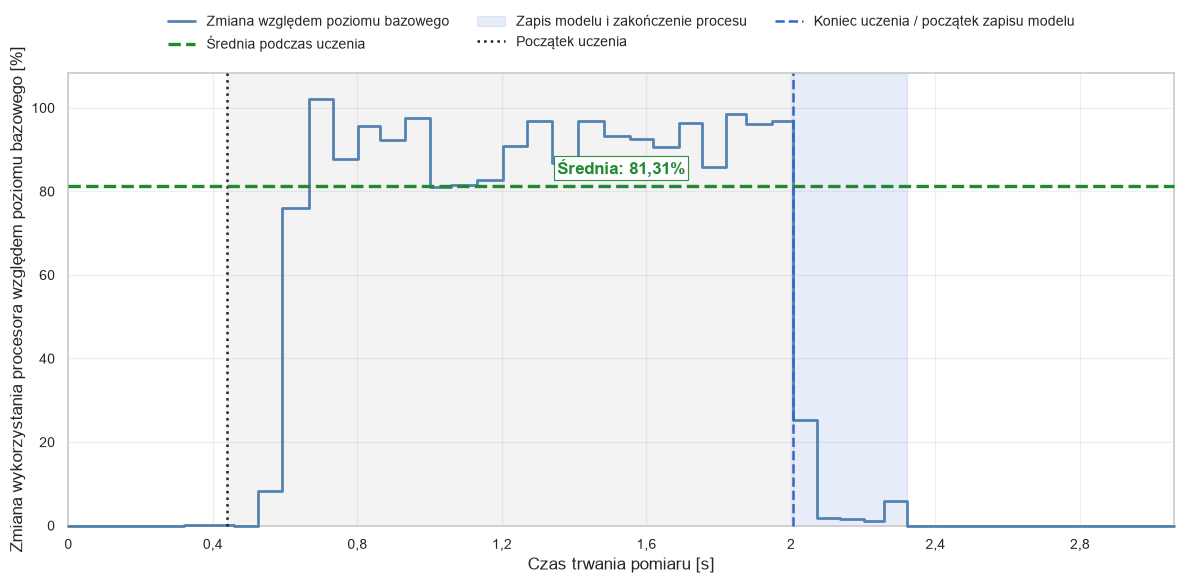

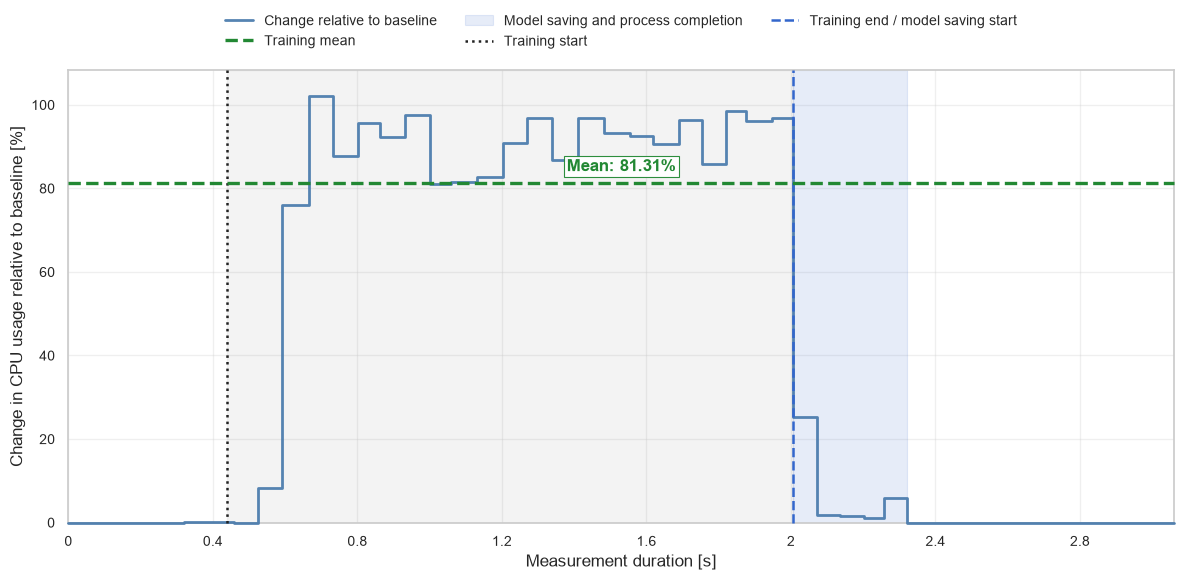

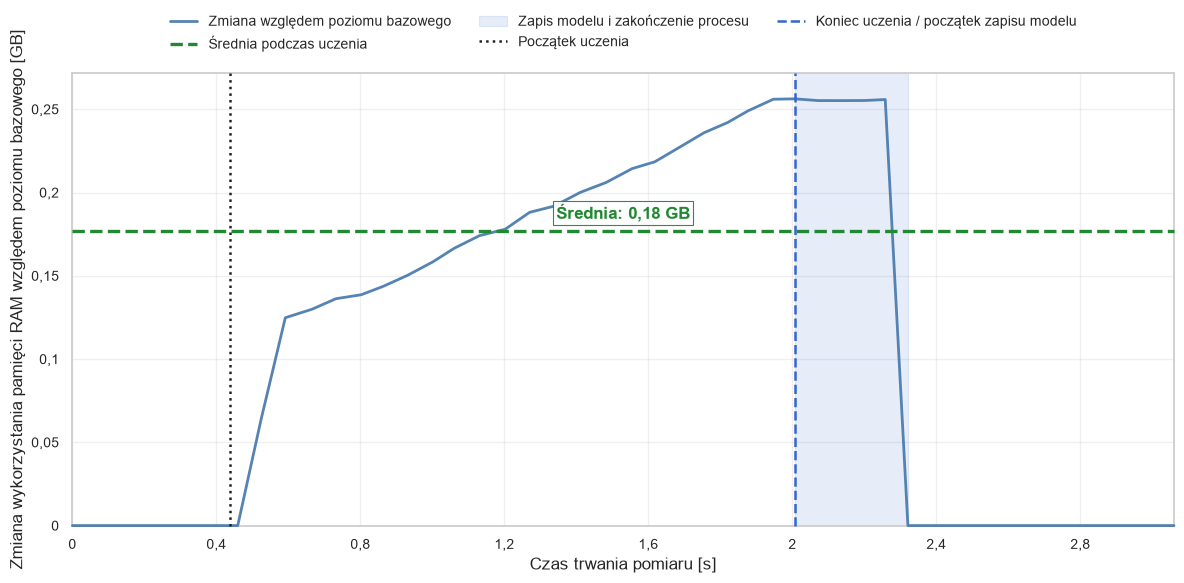

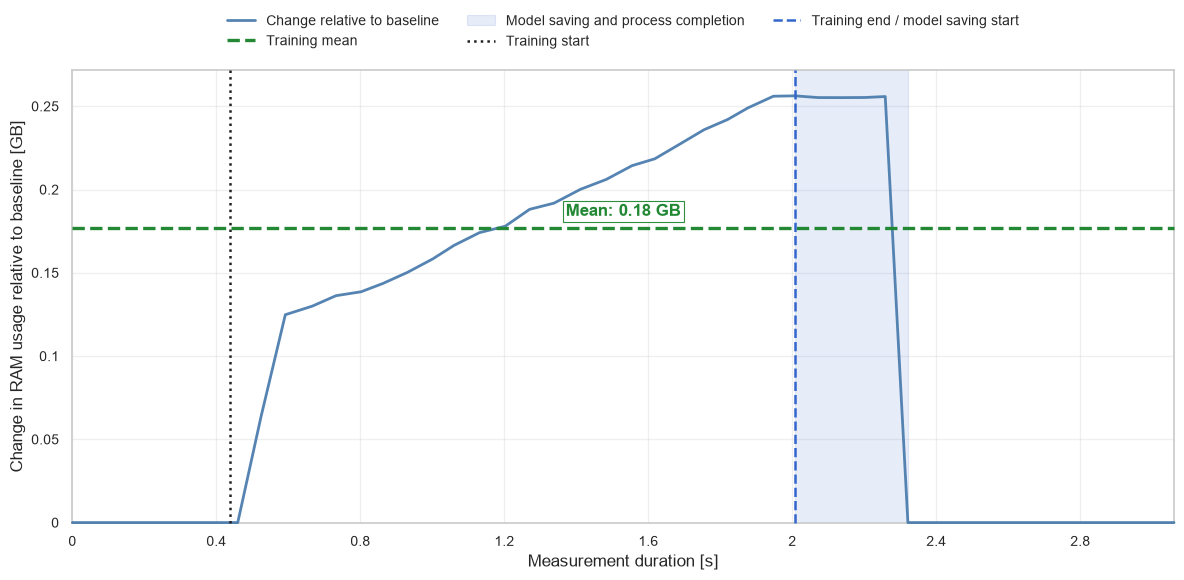

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/resource_usage/random_forest_full.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/random_forest/full/pl/random_forest_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/random_forest/full/pl/random_forest_resource_usage_ram.png


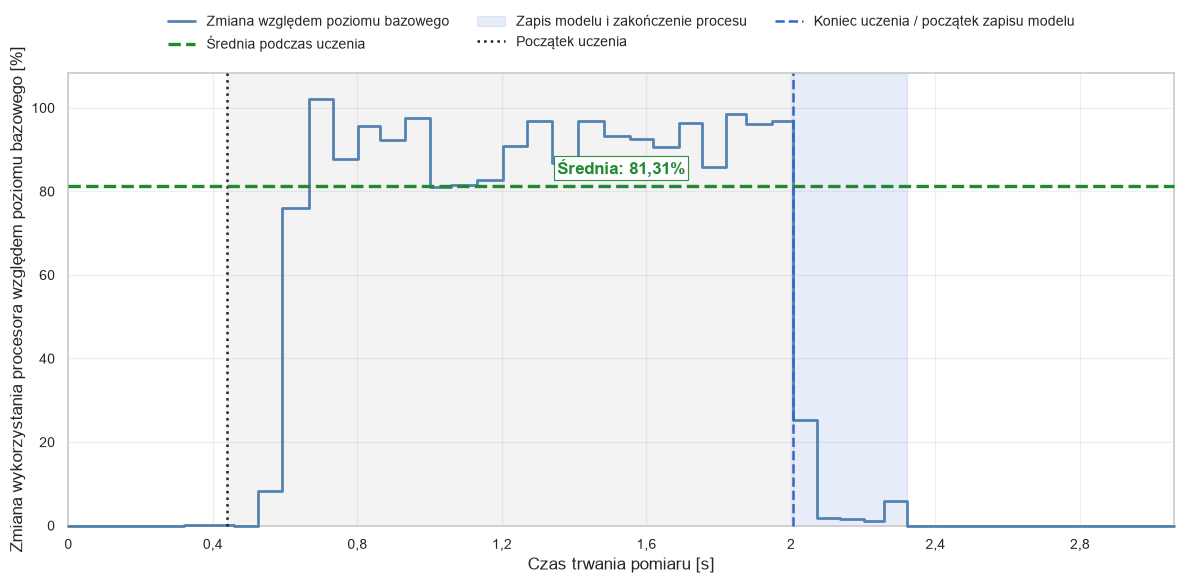

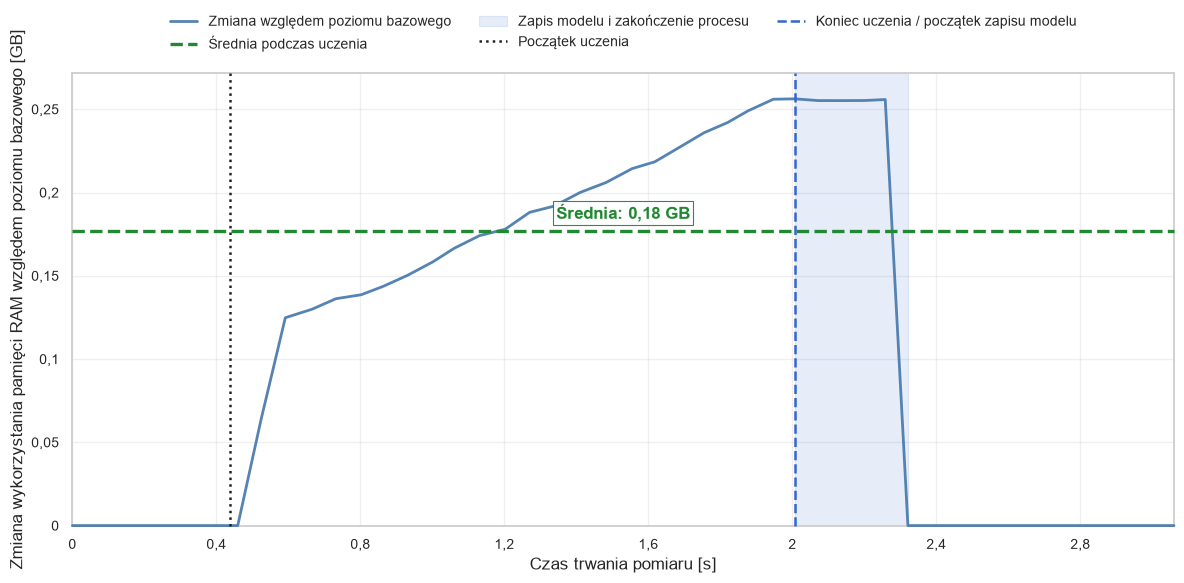

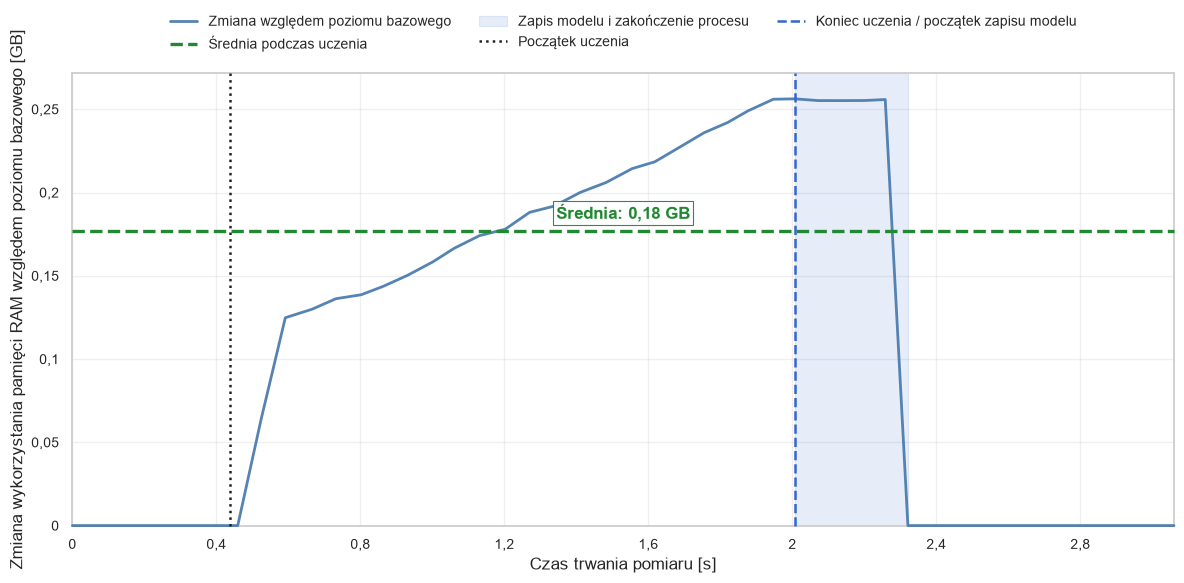

Poziom bazowy to mediana 7 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,04% łącznej mocy 11 rdzeni logicznych; RAM: 0,20 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


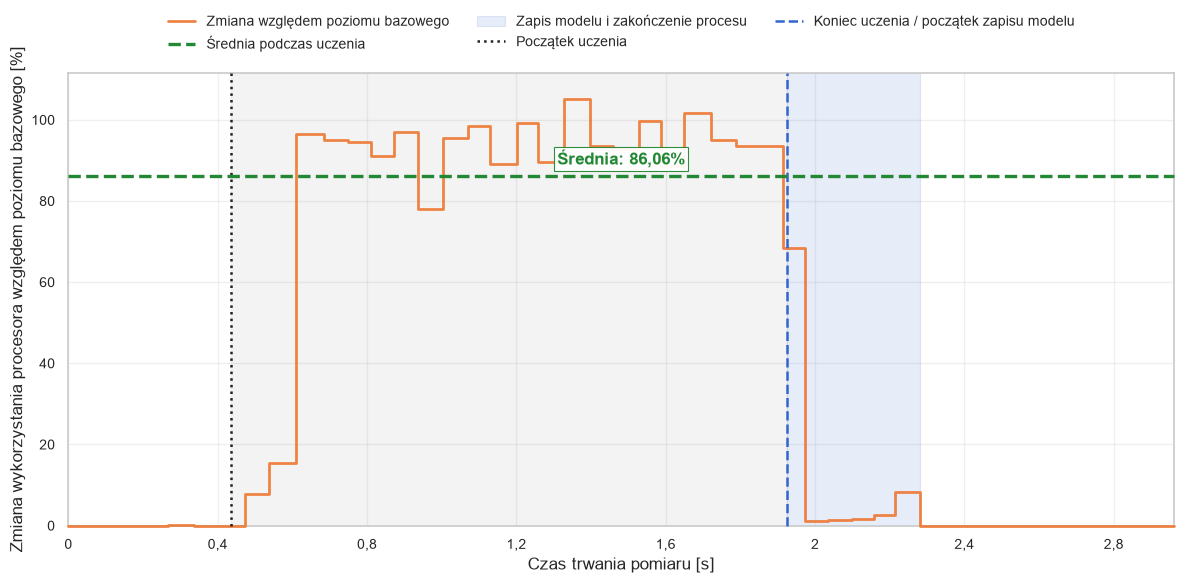

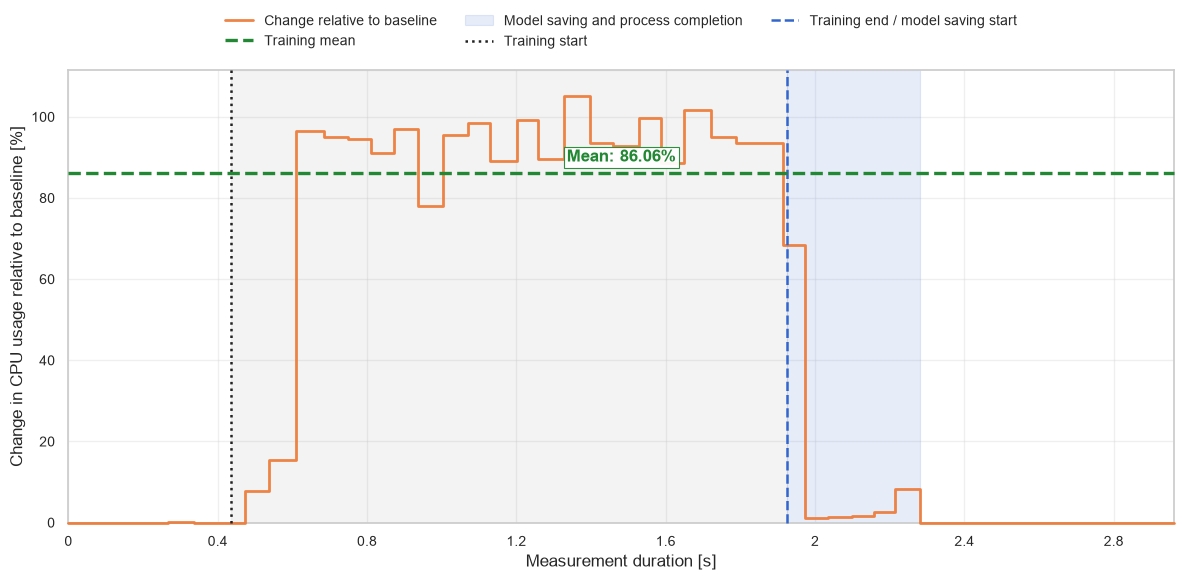

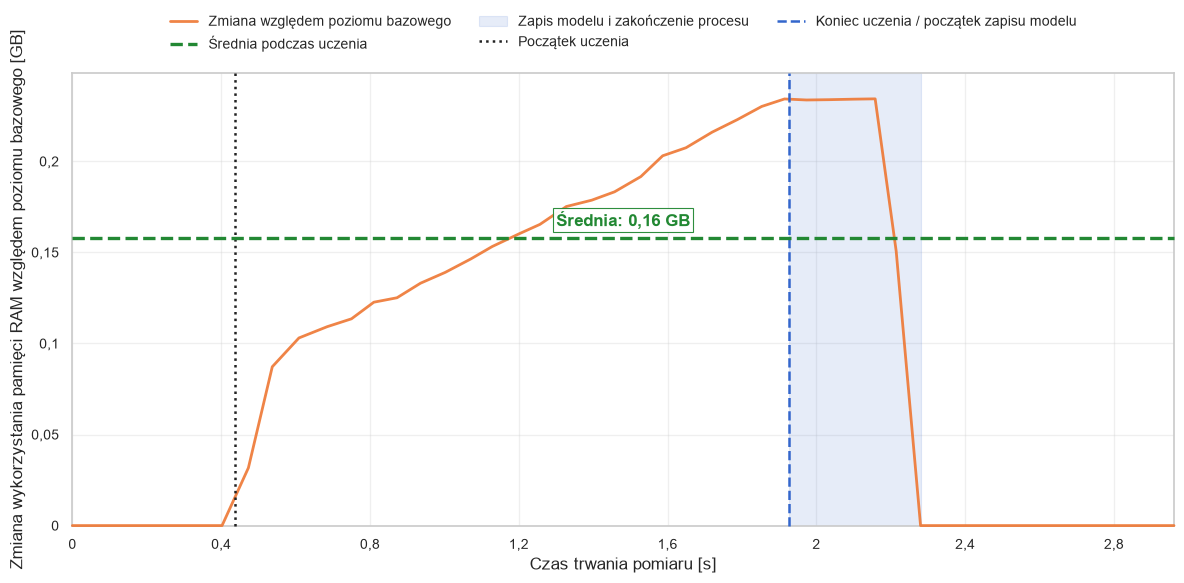

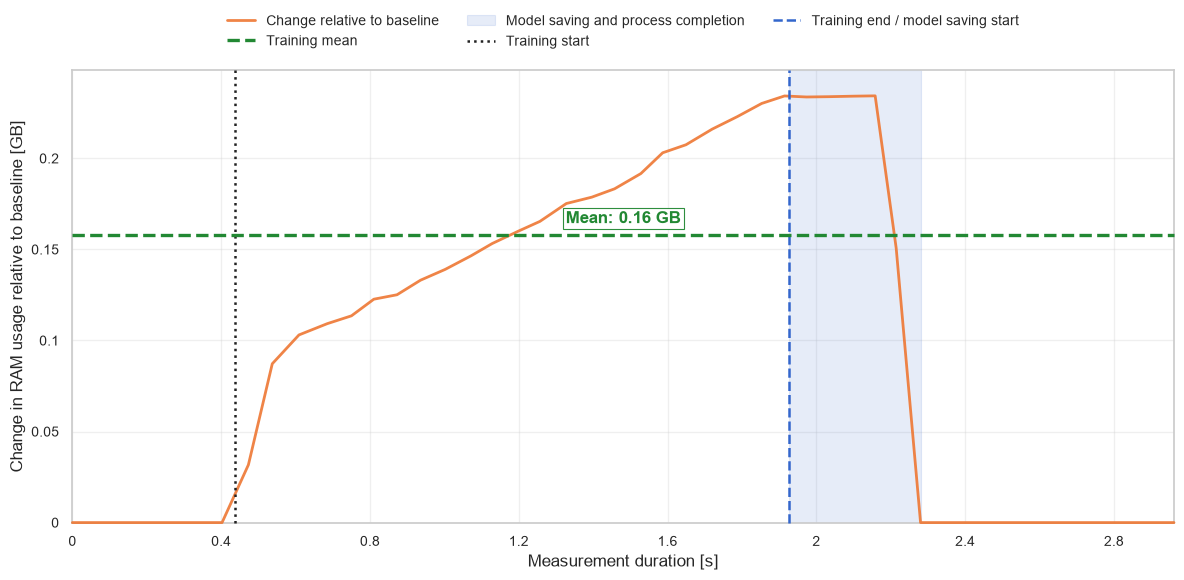

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/resource_usage/random_forest_optimized.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/random_forest/optimized/pl/random_forest_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/random_forest/optimized/pl/random_forest_resource_usage_ram.png


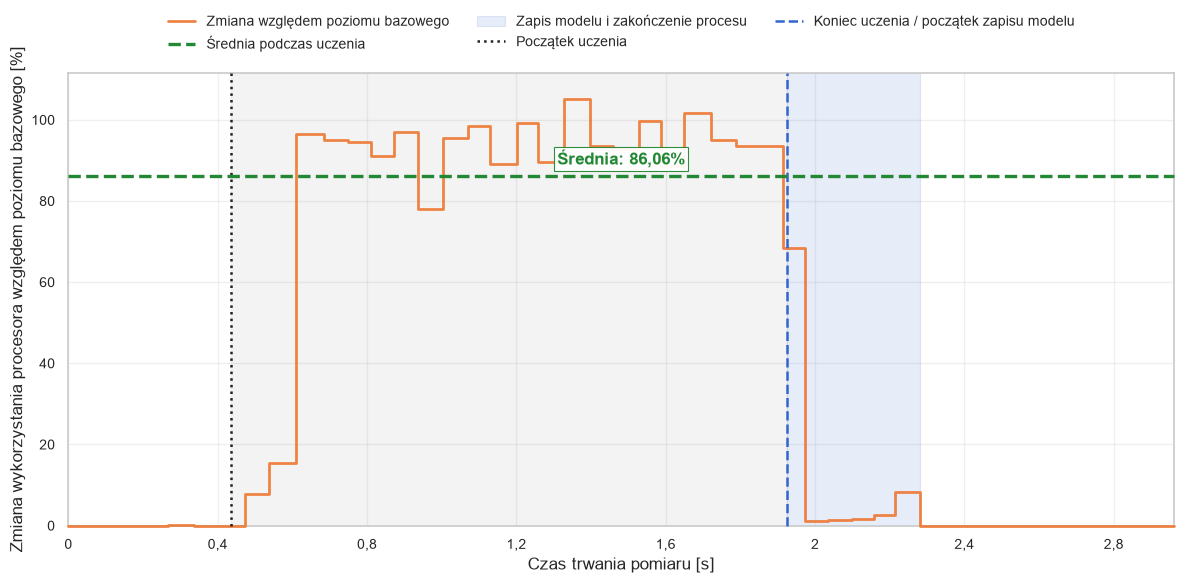

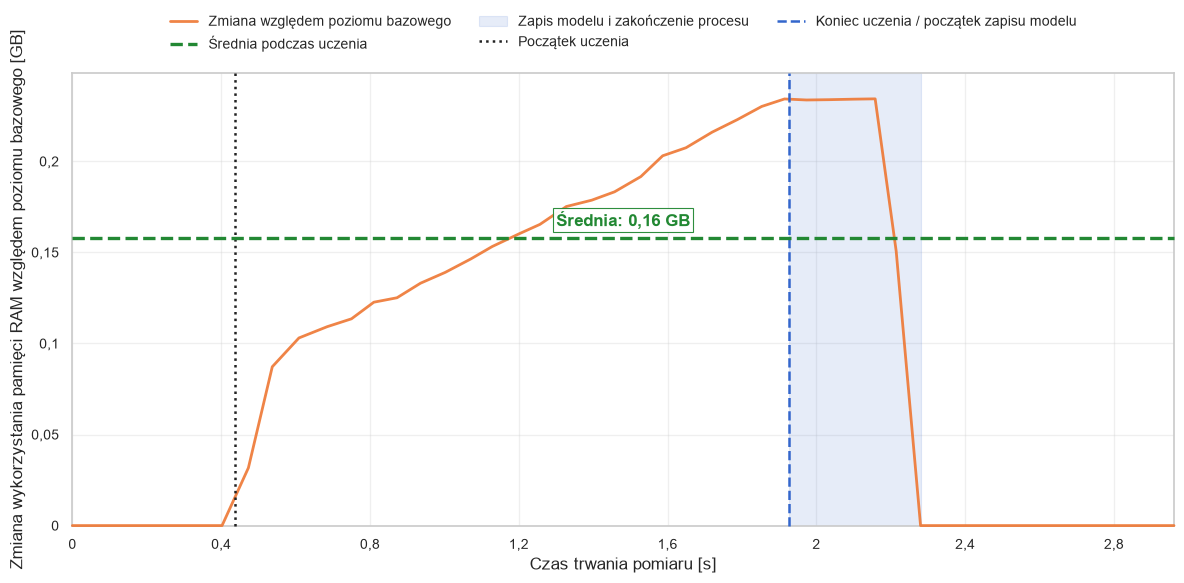

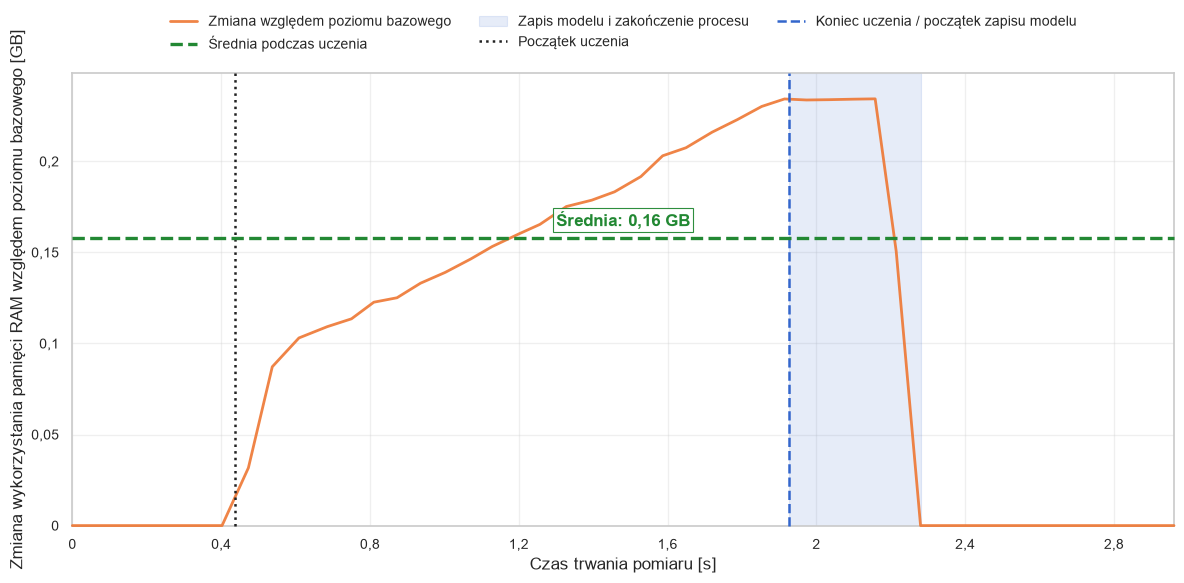

In [7]:
from IPython.display import display

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    monitor = resource_stats[dataset_name]['monitor']
    stats = resource_stats[dataset_name]['stats']
    print(resource_baseline_summary(monitor))
    trace_dir = backend_root.parent / 'results' / 'original' / 'resource_usage'
    trace_dir.mkdir(parents=True, exist_ok=True)
    trace_path = trace_dir / f"random_forest_{dataset_key(dataset_name)}.csv"
    monitor.save_phase_trace(trace_path)
    cpu_figure, ram_figure = plot_resource_usage_separate(monitor, stats, dataset_name, include_post_training=True)
    cpu_path = save_dataset_figure(cpu_figure, PLOTS_DIR, dataset_name, 'random_forest_resource_usage_cpu.png')
    ram_path = save_dataset_figure(ram_figure, PLOTS_DIR, dataset_name, 'random_forest_resource_usage_ram.png')
    print(f'Zapisano ślad: {trace_path}')
    print(f'Zapisano wykres CPU: {cpu_path}')
    print(f'Zapisano wykres RAM: {ram_path}')
    display(cpu_figure)
    display(ram_figure)
    plt.close(cpu_figure)
    plt.close(ram_figure)
    plt.show()


## 6. Porównanie wyników uczenia i testowania

Miary dla procesu uczenia obliczane są na zbiorze uczącym, a miary testowe na
niezależnym zbiorze testowym. Każda miara jest prezentowana na osobnym wykresie
i wykorzystuje wyniki uzyskane przez wytrenowany model, bez jego ponownego
uczenia na potrzeby wizualizacji.

Walidacja oznacza ocenę modelu na danych, które nie uczestniczyły w jego
dopasowaniu w danym przebiegu, ale nadal należą do części danych przeznaczonej
do opracowania modelu. Nie jest ona testem końcowym. Dla każdego rozmiaru
podzbioru uczącego linia uczenia i linia walidacji przedstawiają średnią z pięciu
przebiegów, a półprzezroczyste pasmo przedstawia jedno odchylenie standardowe.
Niezależny zbiór testowy nie uczestniczy w wyznaczaniu tych krzywych.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.



EWALUACJA MODELU - PEŁNY ZBIÓR



WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9697
  • Precyzja: 0.9648
  • Czułość: 0.9749
  • Miara F1 (F1-Score): 0.9698
  • AUC-ROC: 0.9952
  • Błąd uczenia: 0.0000
  • Błąd testowania: 0.0303


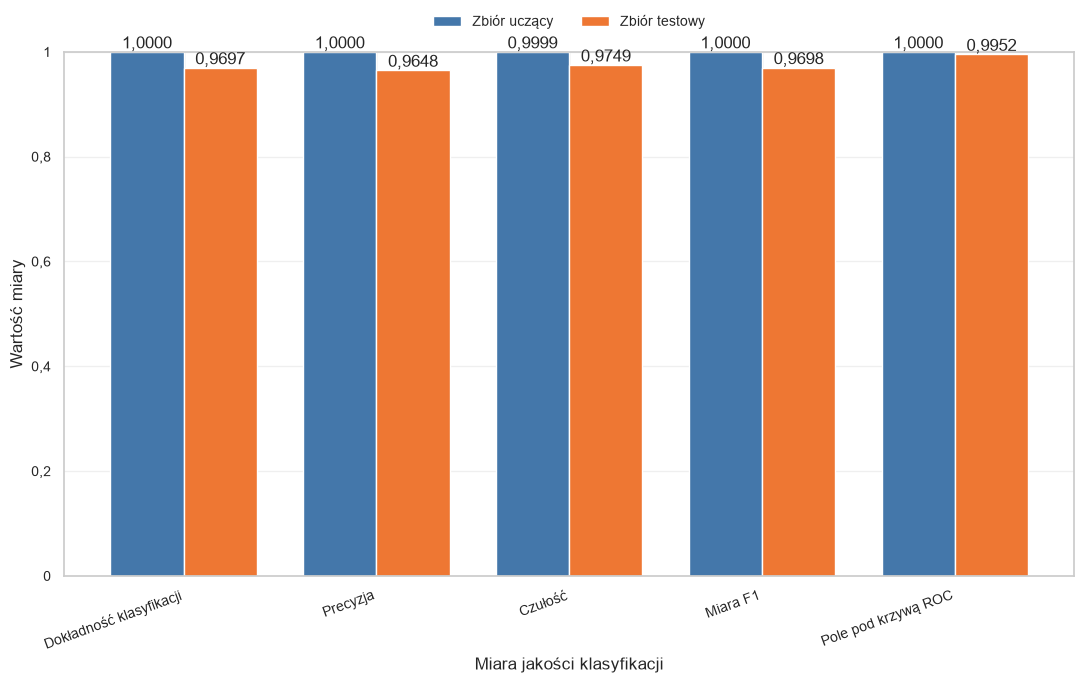

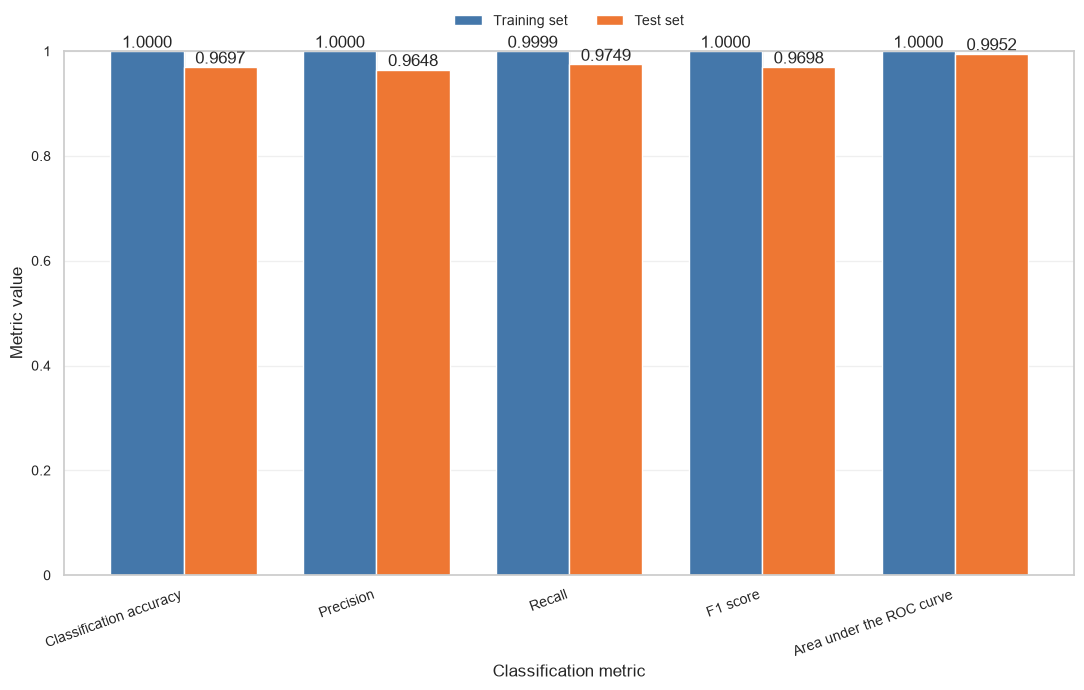

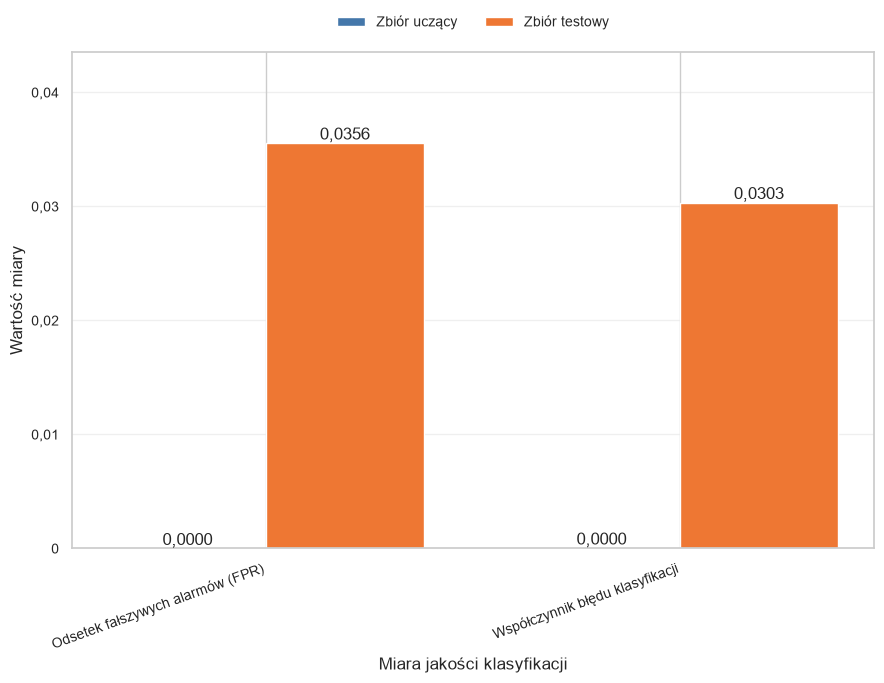

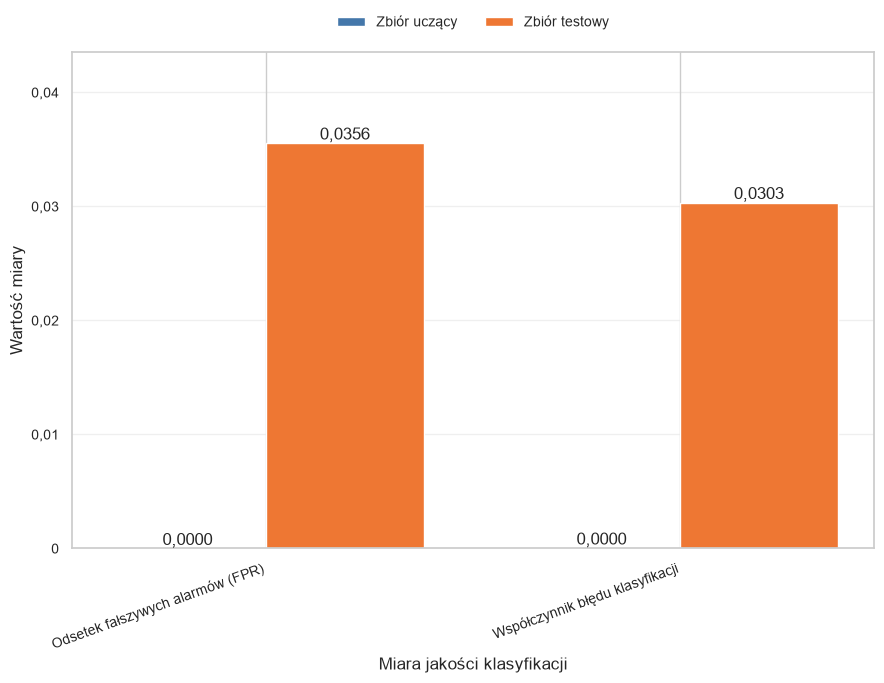

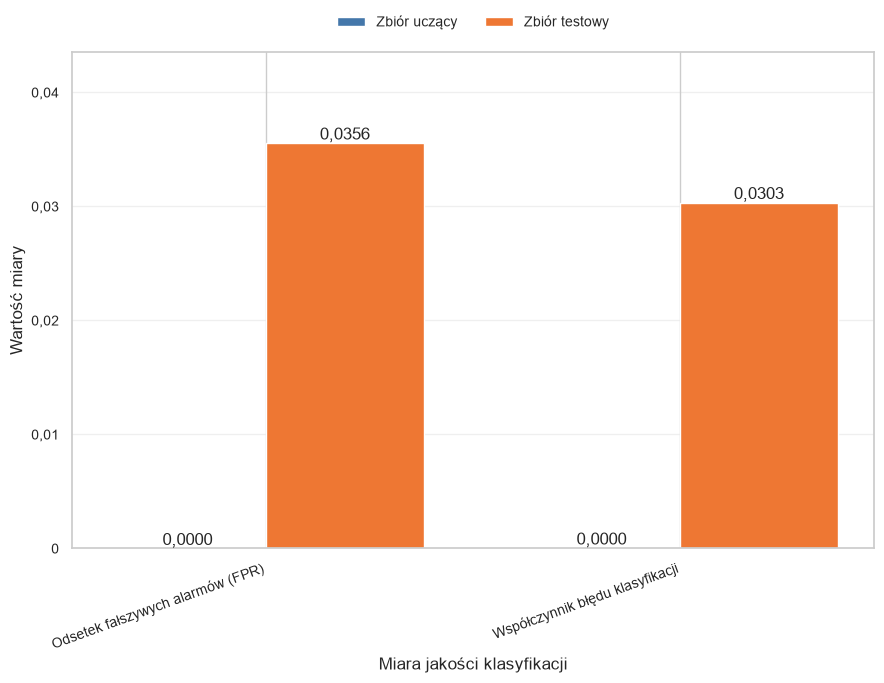

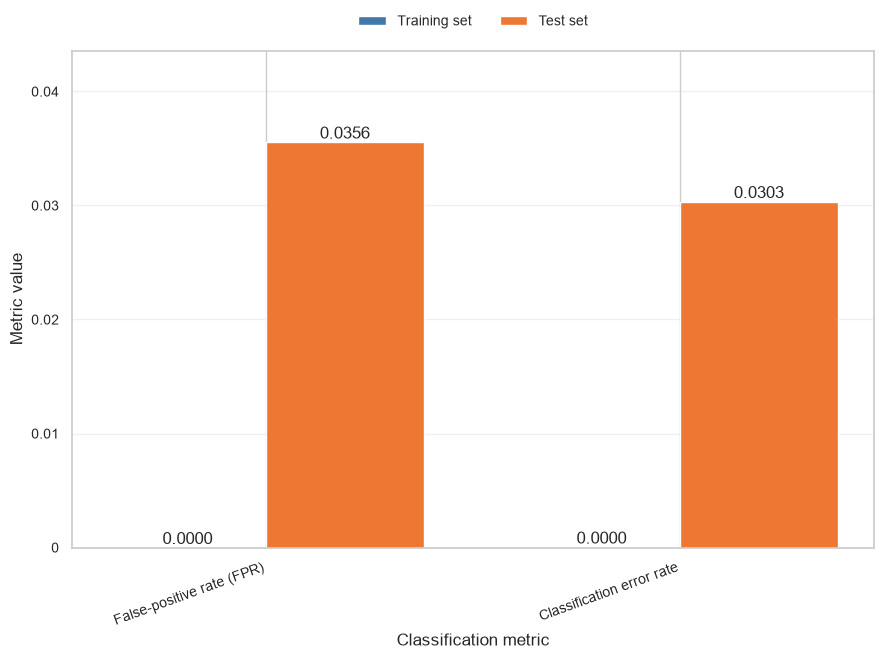


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 5,912
  • Fałszywie pozytywne (FP): 218
  • Fałszywie negatywne (FN): 154
  • Prawdziwie pozytywne (TP): 5,975

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9945 ± 0.0004
  • Min: 0.9939
  • Max: 0.9950

EWALUACJA MODELU - ZOPTYMALIZOWANY ZBIÓR



WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9687
  • Precyzja: 0.9655
  • Czułość: 0.9721
  • Miara F1 (F1-Score): 0.9688
  • AUC-ROC: 0.9946
  • Błąd uczenia: 0.0001
  • Błąd testowania: 0.0313


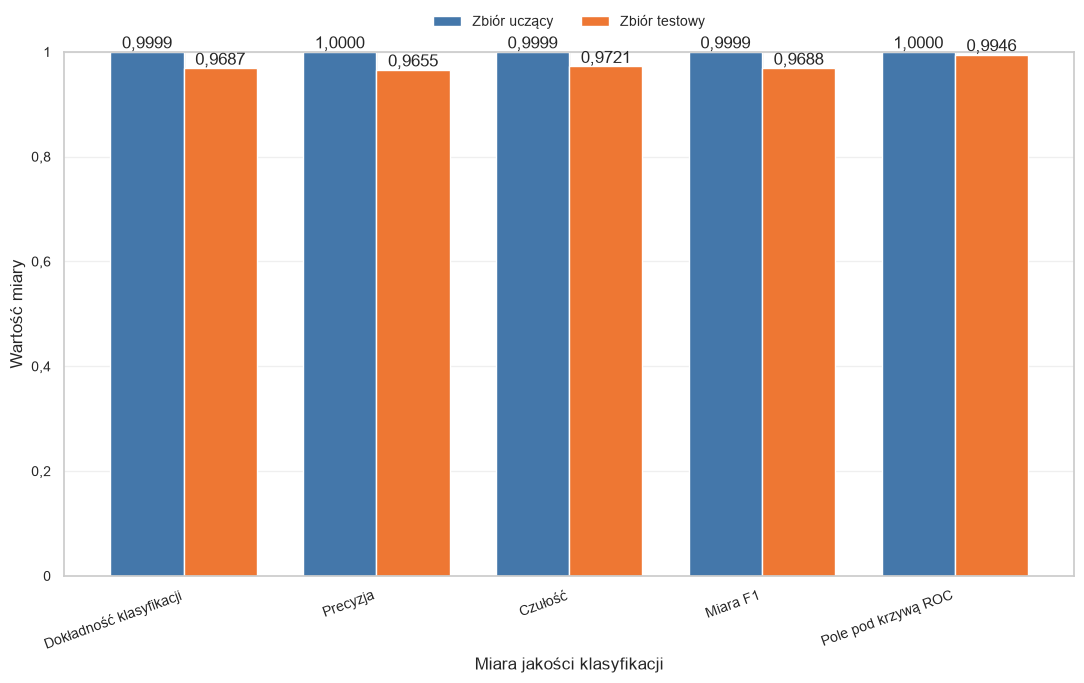

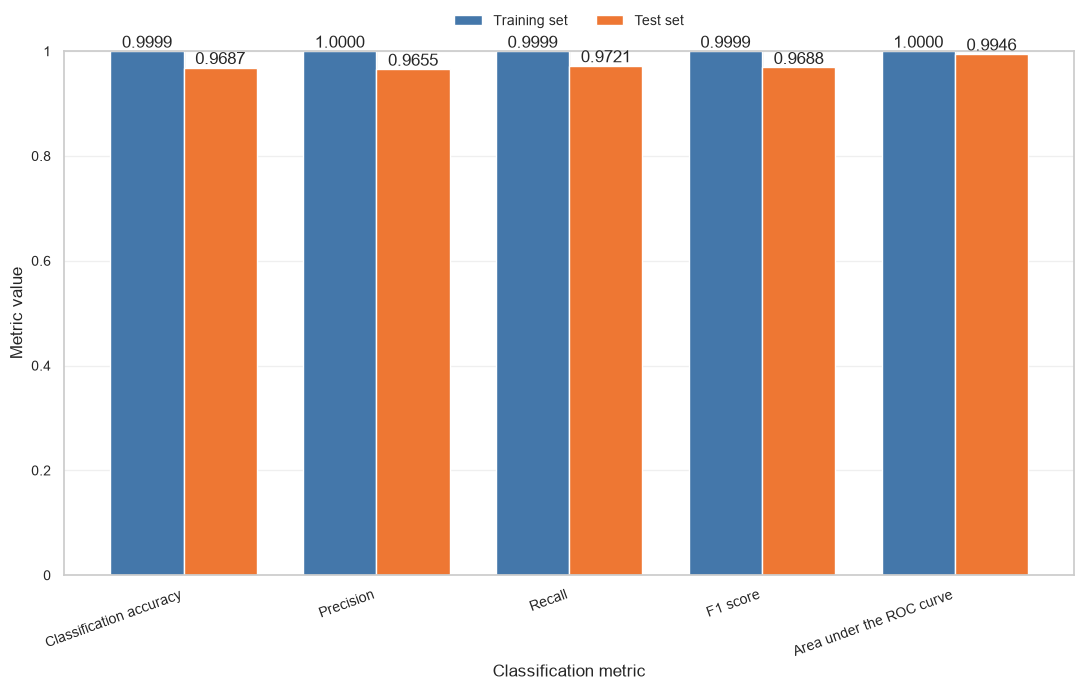

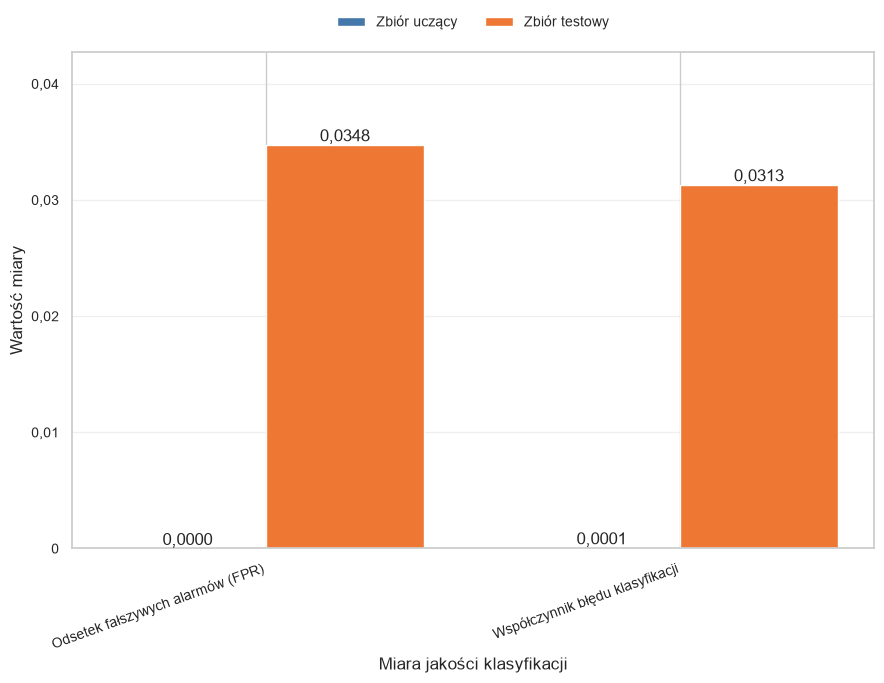

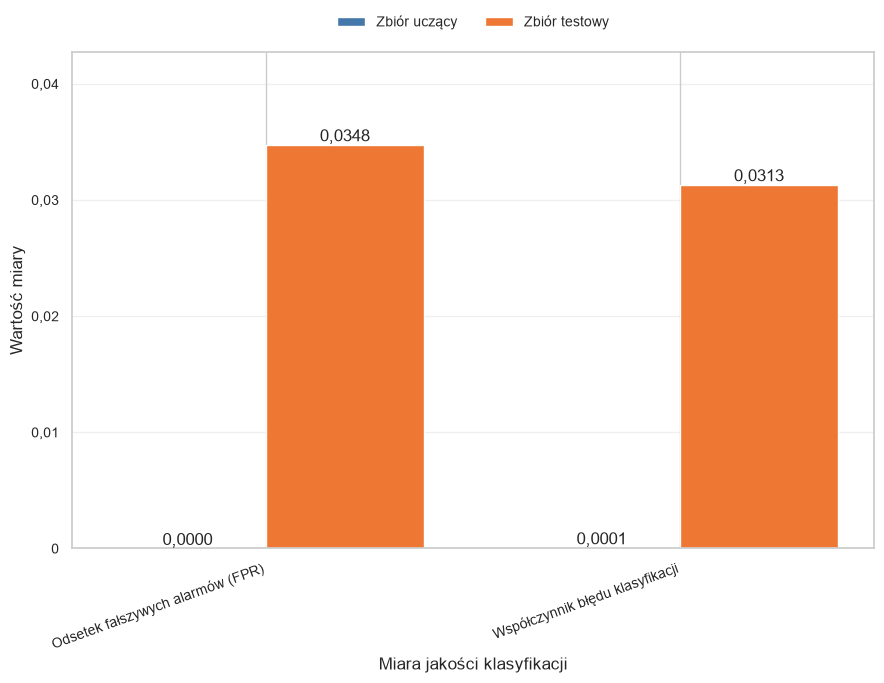

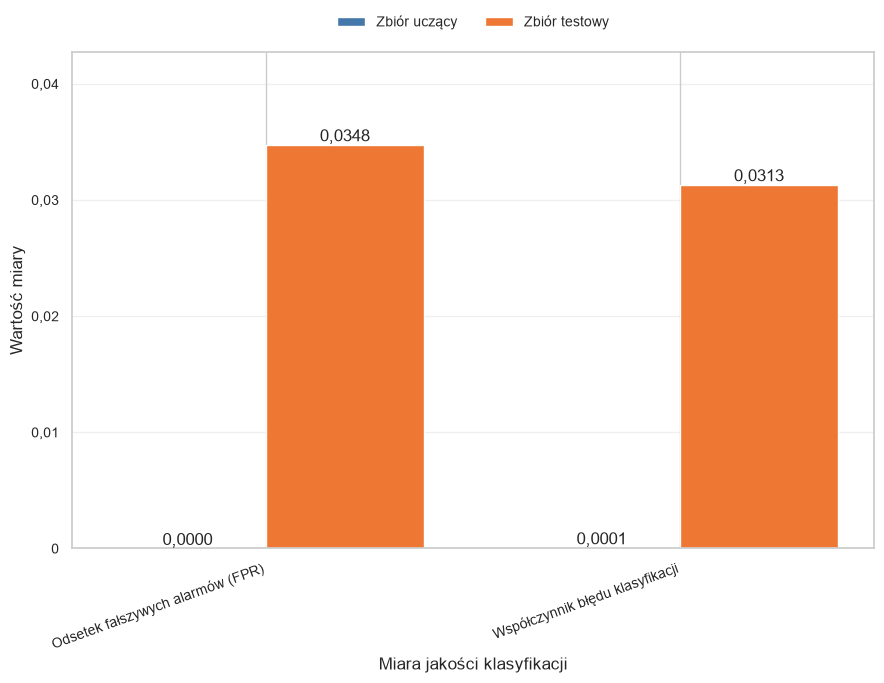

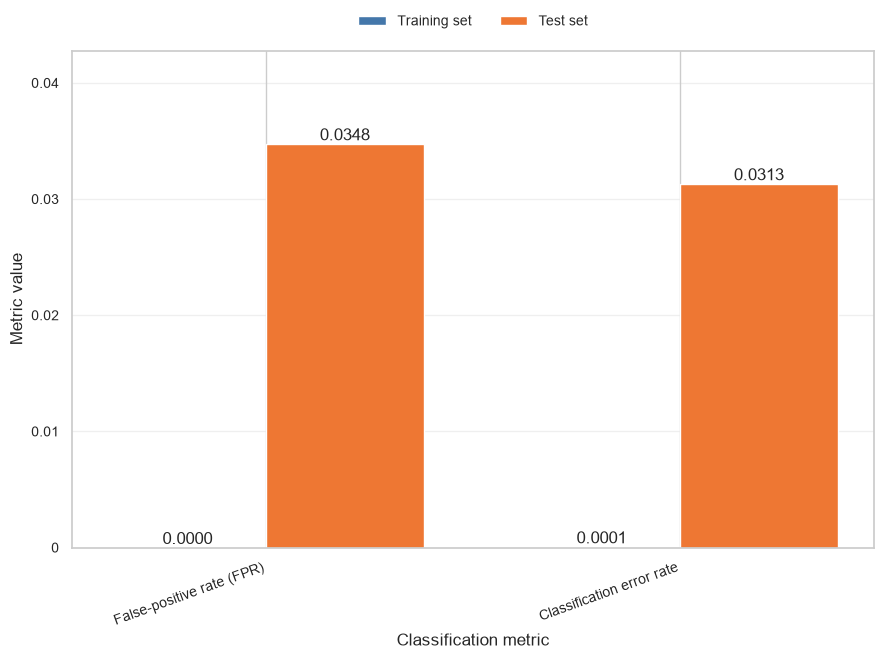


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 5,888
  • Fałszywie pozytywne (FP): 212
  • Fałszywie negatywne (FN): 170
  • Prawdziwie pozytywne (TP): 5,929

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9944 ± 0.0003
  • Min: 0.9940
  • Max: 0.9946

PORÓWNANIE WYNIKÓW
Metryka                  Pełny zbiór Zoptymalizowany zbiór
--------------------------------------------------------------------------------
Accuracy                      0.9697          0.9687 (-0.0010)
Precision                     0.9648          0.9655 (+0.0007)
Recall                        0.9749          0.9721 (-0.0027)
F1                            0.9698          0.9688 (-0.0010)
Auc_roc                       0.9952          0.9946 (-0.0006)


In [8]:
evaluation_results = {}

for dataset_name, model_data in trained_models.items():
    print(f"\n{'='*80}")
    print(f"EWALUACJA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = model_data['model']
    data = train_test_data[dataset_name]

    X_test = data['X_test']
    y_test = data['y_test']
    X_train = data['X_train']
    y_train = data['y_train']

    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    y_train_pred = model.predict(X_train)
    y_train_proba = model.predict_proba(X_train)[:, 1]

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    train_cm = confusion_matrix(y_train, y_train_pred)
    train_tn, train_fp, train_fn, train_tp = train_cm.ravel()

    accuracy = accuracy_score(y_test, y_pred)
    train_accuracy = accuracy_score(y_train, y_train_pred)
    train_error_rate = 1.0 - accuracy_score(y_train, y_train_pred)
    test_error_rate = 1.0 - accuracy
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    train_precision = precision_score(y_train, y_train_pred, zero_division=0)
    train_recall = recall_score(y_train, y_train_pred, zero_division=0)
    train_f1 = f1_score(y_train, y_train_pred, zero_division=0)
    false_positive_rate = fp / (fp + tn) if (fp + tn) else 0.0
    train_false_positive_rate = train_fp / (train_fp + train_tn) if (train_fp + train_tn) else 0.0
    auc_roc = roc_auc_score(y_test, y_pred_proba)
    train_auc_roc = roc_auc_score(y_train, y_train_proba)
    train_bce = log_loss(y_train, y_train_proba)
    test_bce = log_loss(y_test, y_pred_proba)

    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')

    evaluation_results[dataset_name] = {
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'accuracy': accuracy,
        'train_accuracy': train_accuracy,
        'train_error_rate': train_error_rate,
        'test_error_rate': test_error_rate,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'train_precision': train_precision,
        'train_recall': train_recall,
        'train_f1': train_f1,
        'false_positive_rate': false_positive_rate,
        'train_false_positive_rate': train_false_positive_rate,
        'auc_roc': auc_roc,
        'train_auc_roc': train_auc_roc,
        'train_bce': train_bce,
        'test_bce': test_bce,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }

    print(f"\nWYNIKI NA ZBIORZE TESTOWYM:")
    print(f"  • Dokładność (Accuracy): {accuracy:.4f}")
    print(f"  • Precyzja: {precision:.4f}")
    print(f"  • Czułość: {recall:.4f}")
    print(f"  • Miara F1 (F1-Score): {f1:.4f}")
    print(f"  • AUC-ROC: {auc_roc:.4f}")
    print(f"  • Błąd uczenia: {train_error_rate:.4f}")
    print(f"  • Błąd testowania: {test_error_rate:.4f}")

    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'random_forest_final_error_rate.png'
    )

    train_metrics, test_metrics = classification_metric_sets(
        evaluation_results[dataset_name]
    )
    metric_figures = plot_final_train_test_metric_groups(
        train_metrics, test_metrics
    )
    for group_name, metric_figure in metric_figures.items():
        save_dataset_figure(
            metric_figure, PLOTS_DIR, dataset_name,
            f'random_forest_metrics_{group_name}.png',
        )
        plt.show()

    print(f"\nMACIERZ POMYŁEK:")
    print(f"  • Prawdziwie negatywne (TN): {tn:,}")
    print(f"  • Fałszywie pozytywne (FP): {fp:,}")
    print(f"  • Fałszywie negatywne (FN): {fn:,}")
    print(f"  • Prawdziwie pozytywne (TP): {tp:,}")

    print(f"\nPIĘCIOKROTNA WALIDACJA KRZYŻOWA:")
    print(f"  • Średni wynik ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  • Min: {cv_scores.min():.4f}")
    print(f"  • Max: {cv_scores.max():.4f}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW")
print(f"{'='*80}")
print(f"{'Metryka':<20} {'Pełny zbiór':>15} {'Zoptymalizowany zbiór':>20}")
print(f"{'-'*80}")
for metric in ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']:
    full_val = evaluation_results['Pełny zbiór'][metric]
    opt_val = evaluation_results['Zoptymalizowany zbiór'][metric]
    diff = opt_val - full_val
    diff_str = f"({diff:+.4f})" if diff != 0 else ""
    print(f"{metric.capitalize():<20} {full_val:>15.4f} {opt_val:>15.4f} {diff_str:>5}")

## 7. Wizualizacja kompleksowa i krzywa uczenia


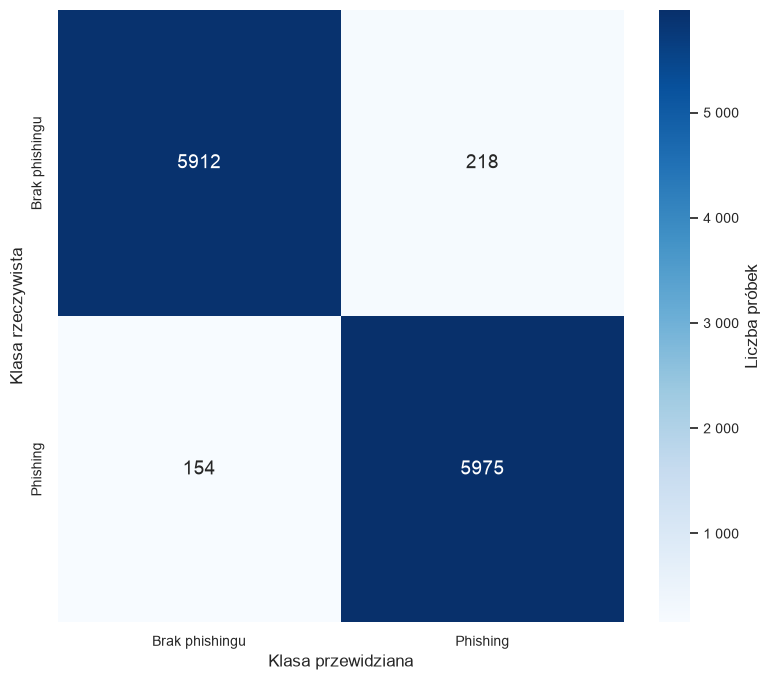

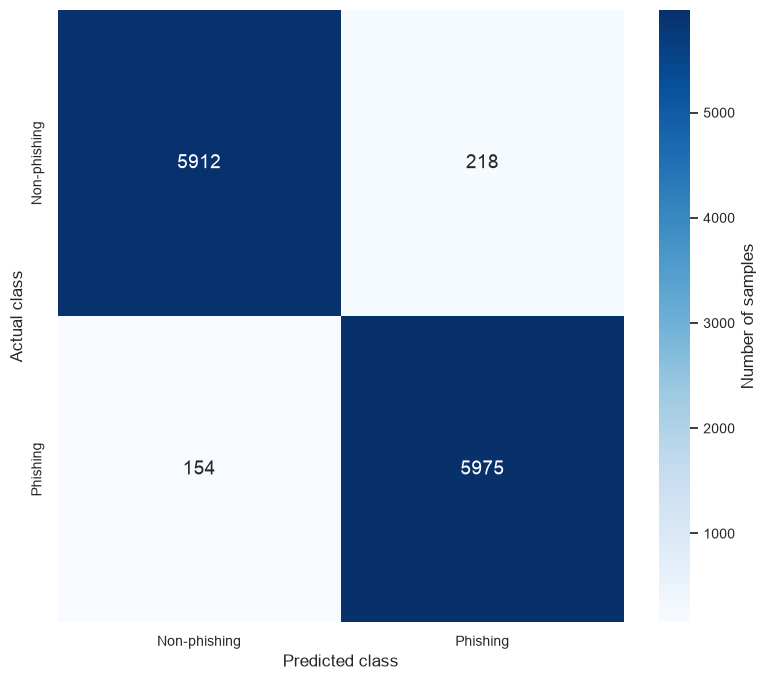

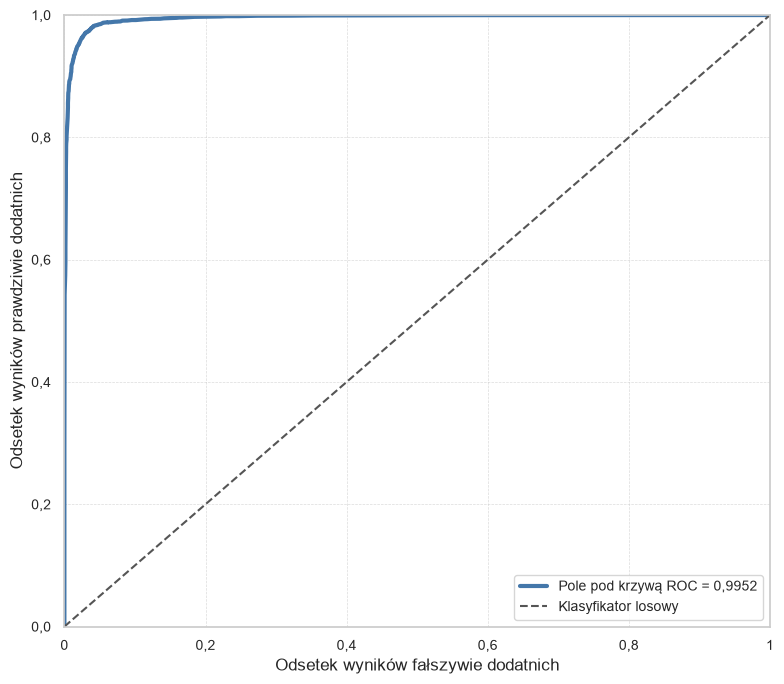

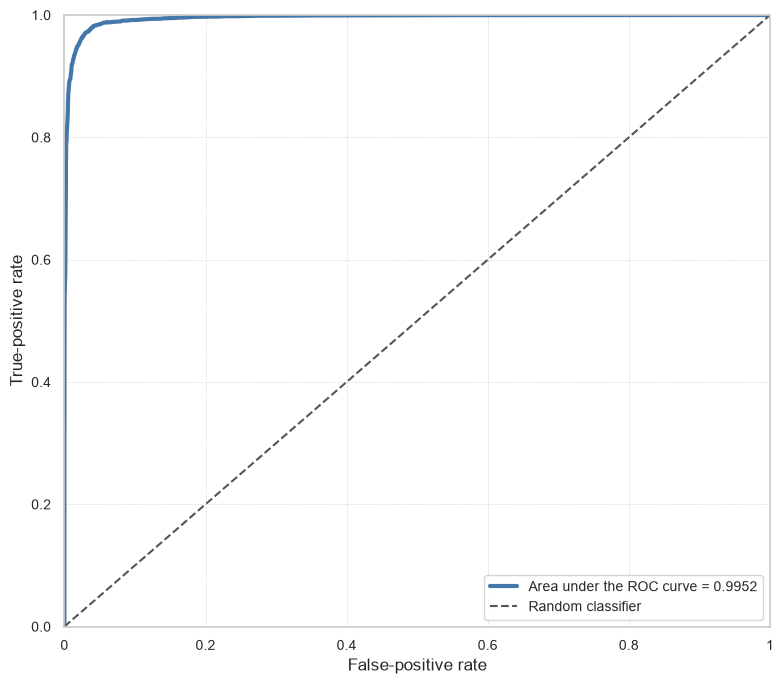

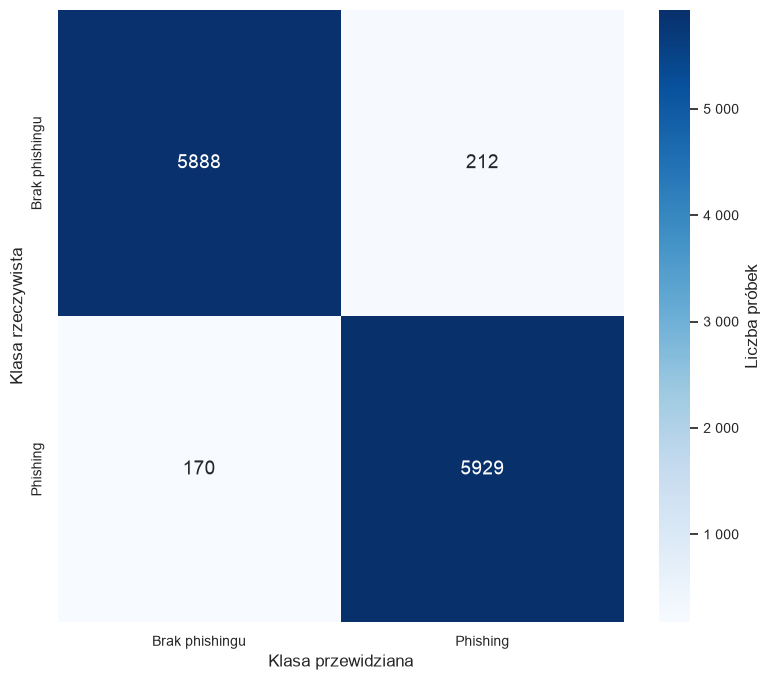

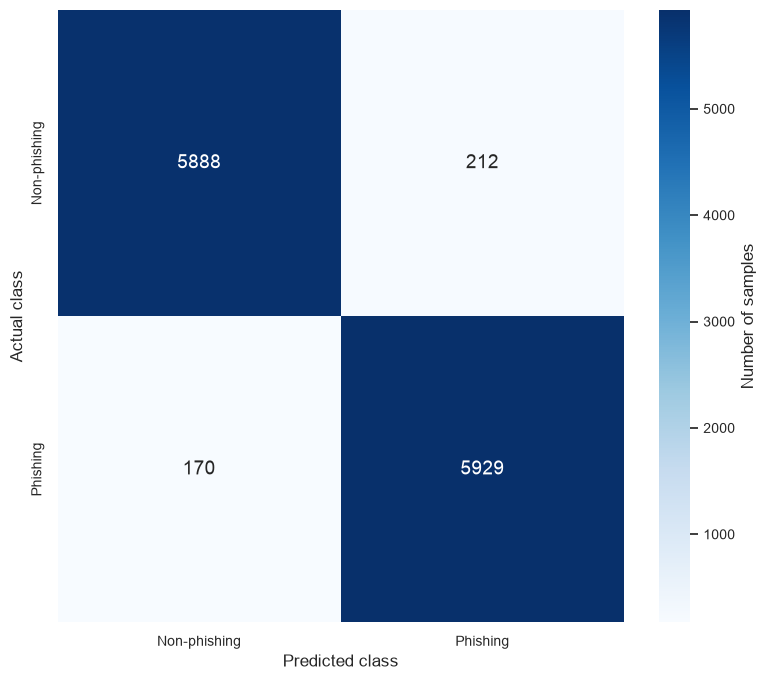

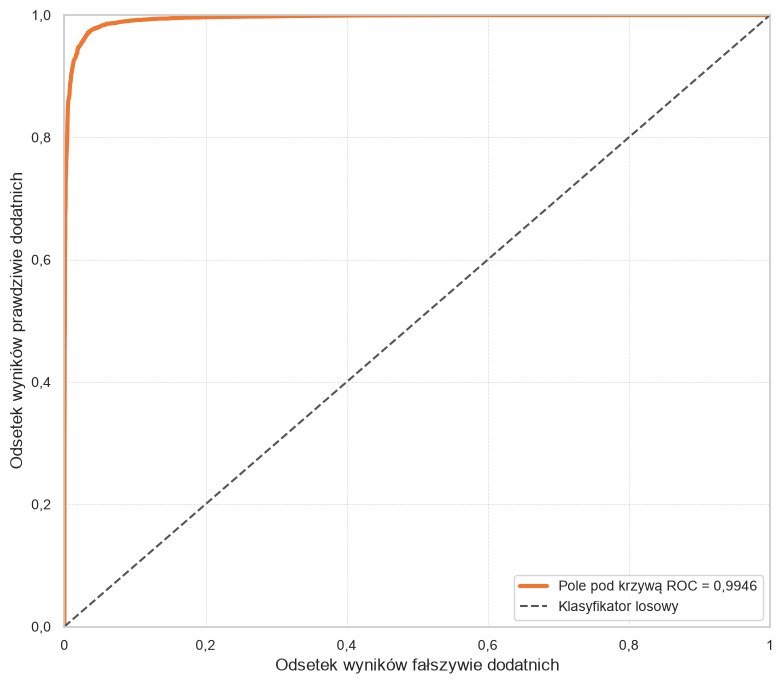

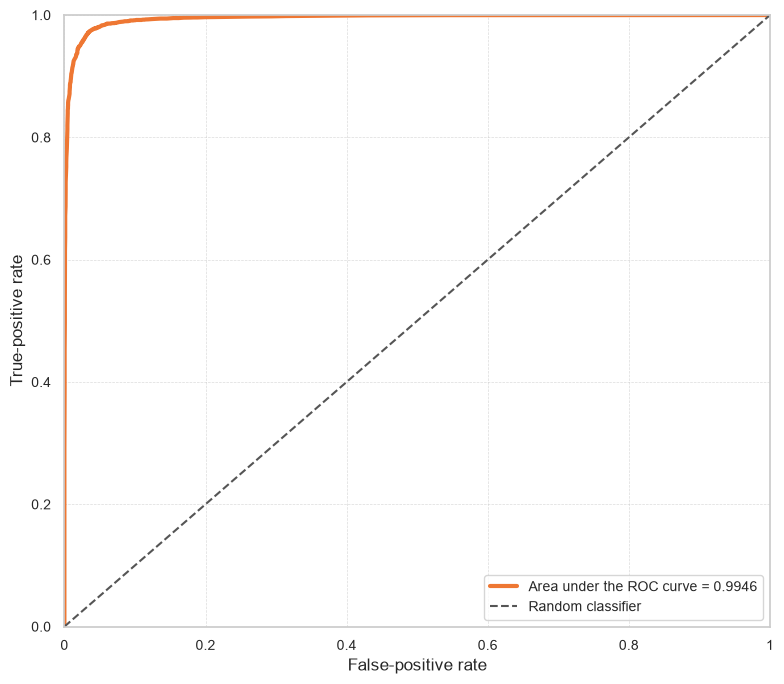

In [9]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    evaluation = evaluation_results[dataset_name]

    confusion_figure, _ = plot_confusion_matrix(
        evaluation['confusion_matrix'], dataset_name,
    )
    save_dataset_figure(
        confusion_figure, PLOTS_DIR, dataset_name, 'random_forest_confusion_matrix.png'
    )
    plt.show()

    roc_figure, _ = plot_roc_curve(
        train_test_data[dataset_name]['y_test'], evaluation['y_pred_proba'], evaluation['auc_roc'], dataset_name,
    )
    save_dataset_figure(
        roc_figure, PLOTS_DIR, dataset_name, 'random_forest_roc_curve.png'
    )
    plt.show()


## 7.1. Porównanie metryk w postaci wykresów słupkowych


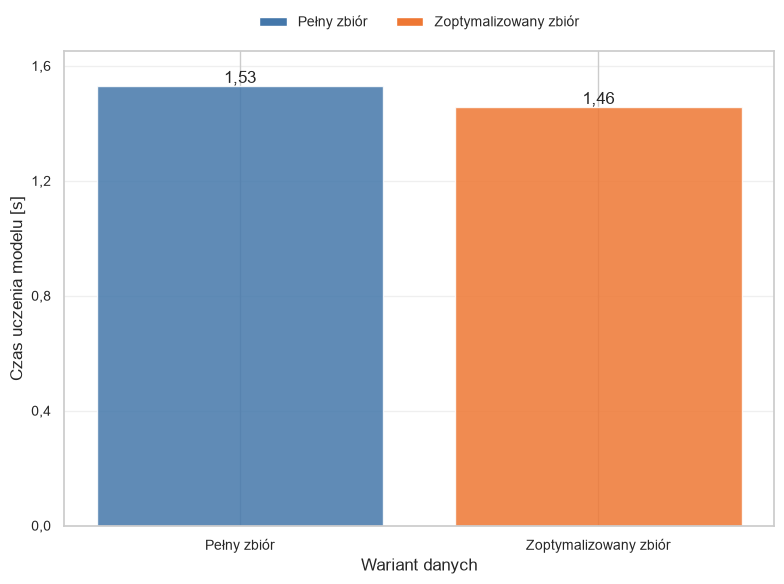

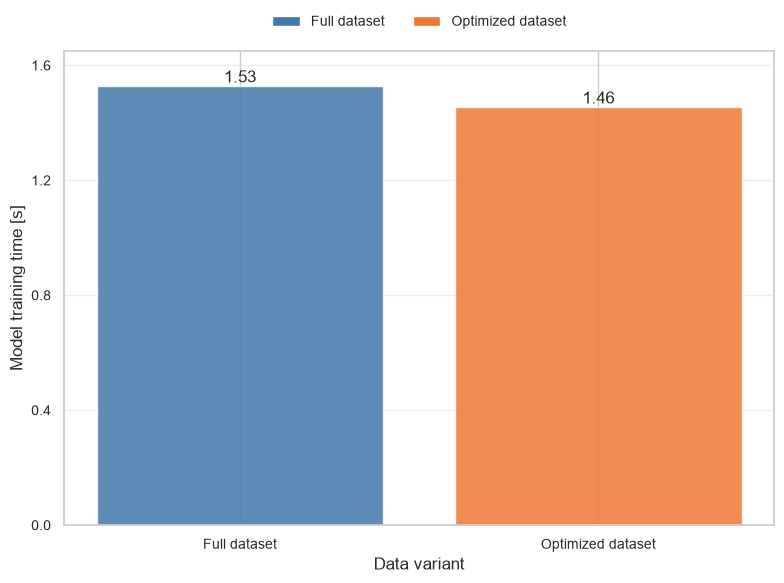

,Wariant danych,Liczba cech,Redukcja liczby cech,Redukcja [%]
0,Pełny zbiór,111,0,0.00
1,Zoptymalizowany zbiór,74,37,33.33


In [10]:
training_times = {}
feature_counts = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    training_times[dataset_name] = float(trained_models[dataset_name]['training_time'])
    feature_counts[dataset_name] = int(data_splits[dataset_name]['feature_count'])
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'random_forest_training_time.png'
    )
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'random_forest_feature_count.png'
    )

time_figure, _ = plot_training_time_comparison(training_times)
save_comparison_figure(
    time_figure, PLOTS_DIR / 'random_forest_training_time_comparison.png'
)
plt.show()

feature_count_rows = feature_count_comparison_rows(
    feature_counts['Pełny zbiór'],
    feature_counts['Zoptymalizowany zbiór'],
)
display(pd.DataFrame(feature_count_rows))


## 7.1a. Wizualizacja przykładowego drzewa decyzyjnego z lasu


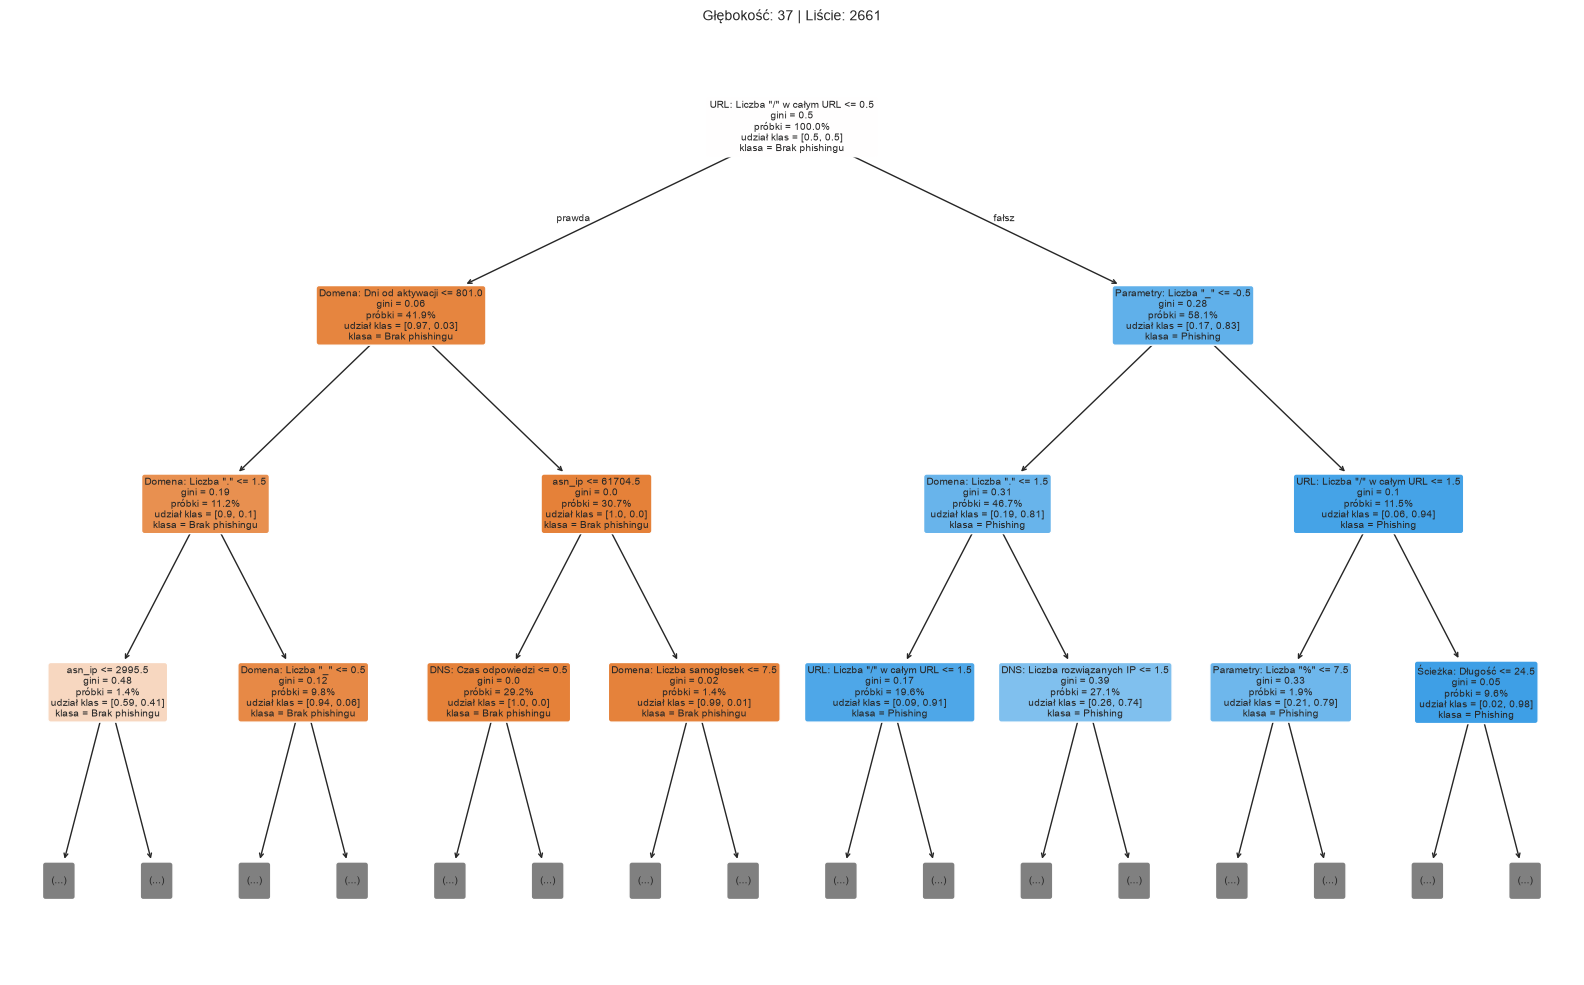

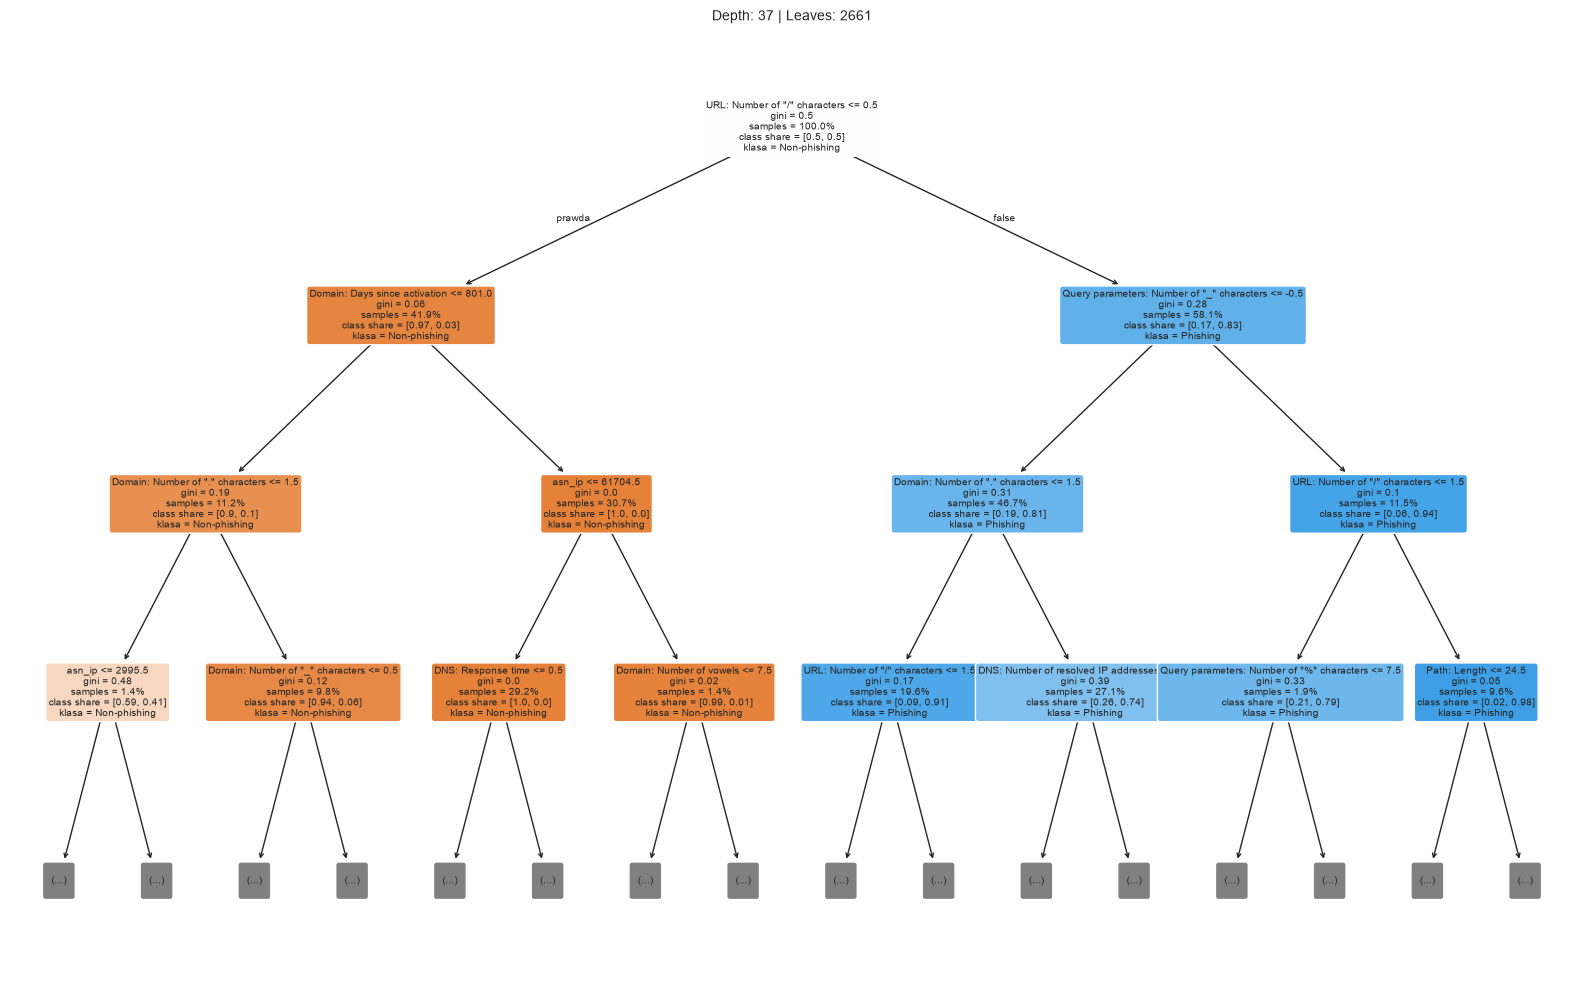

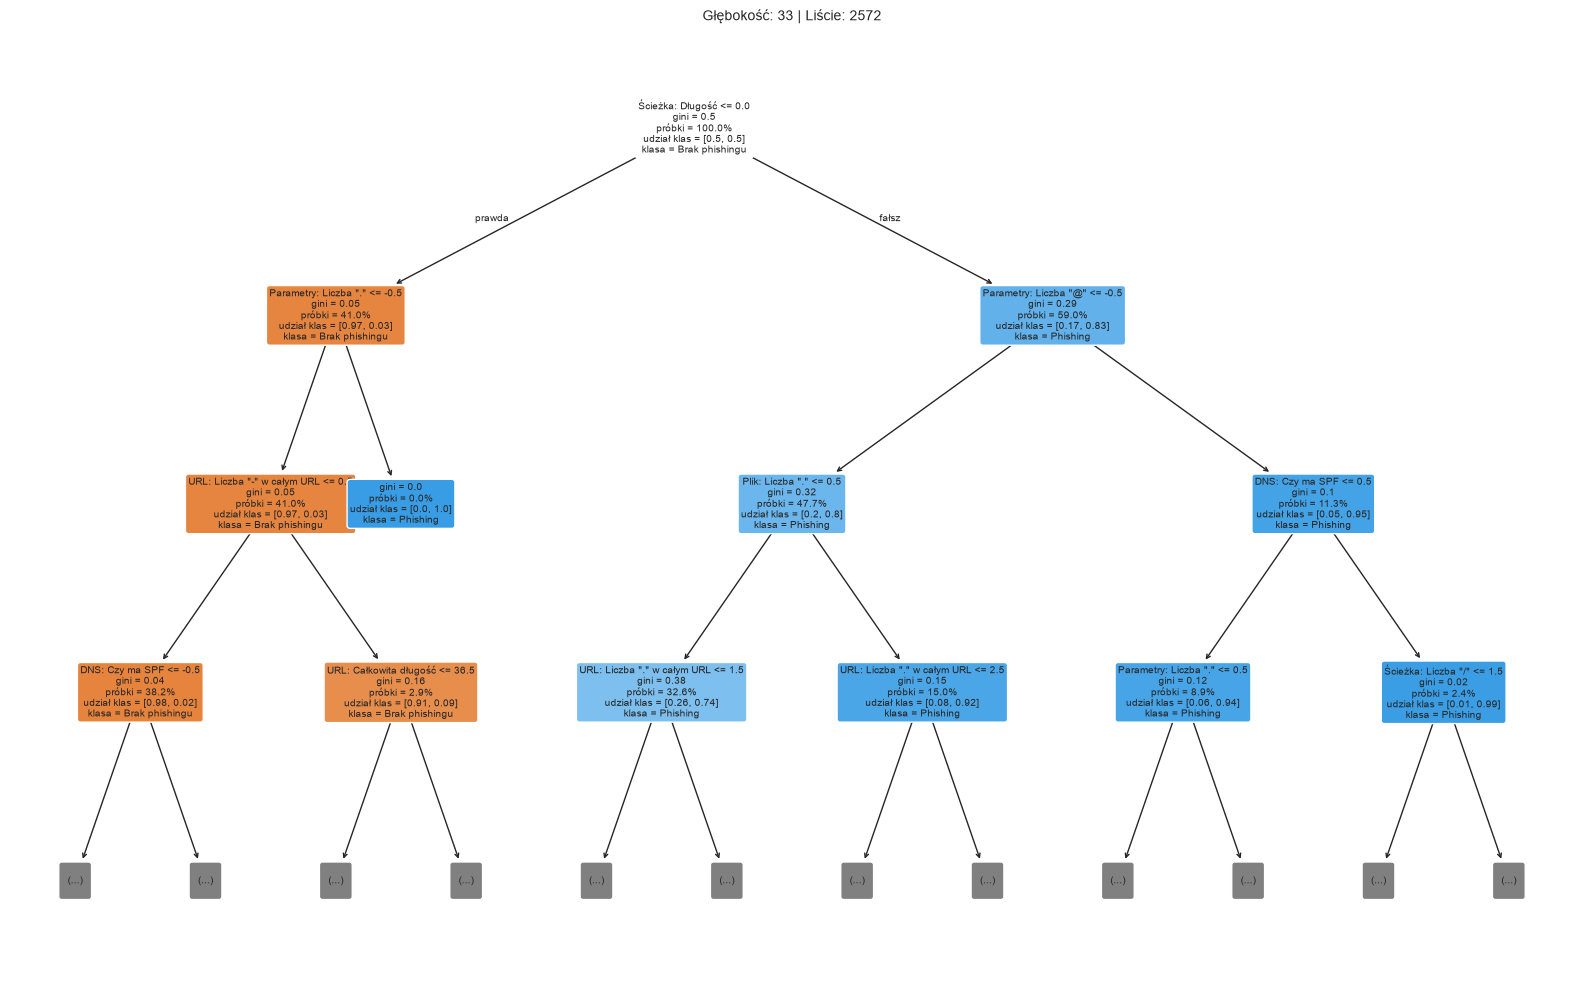

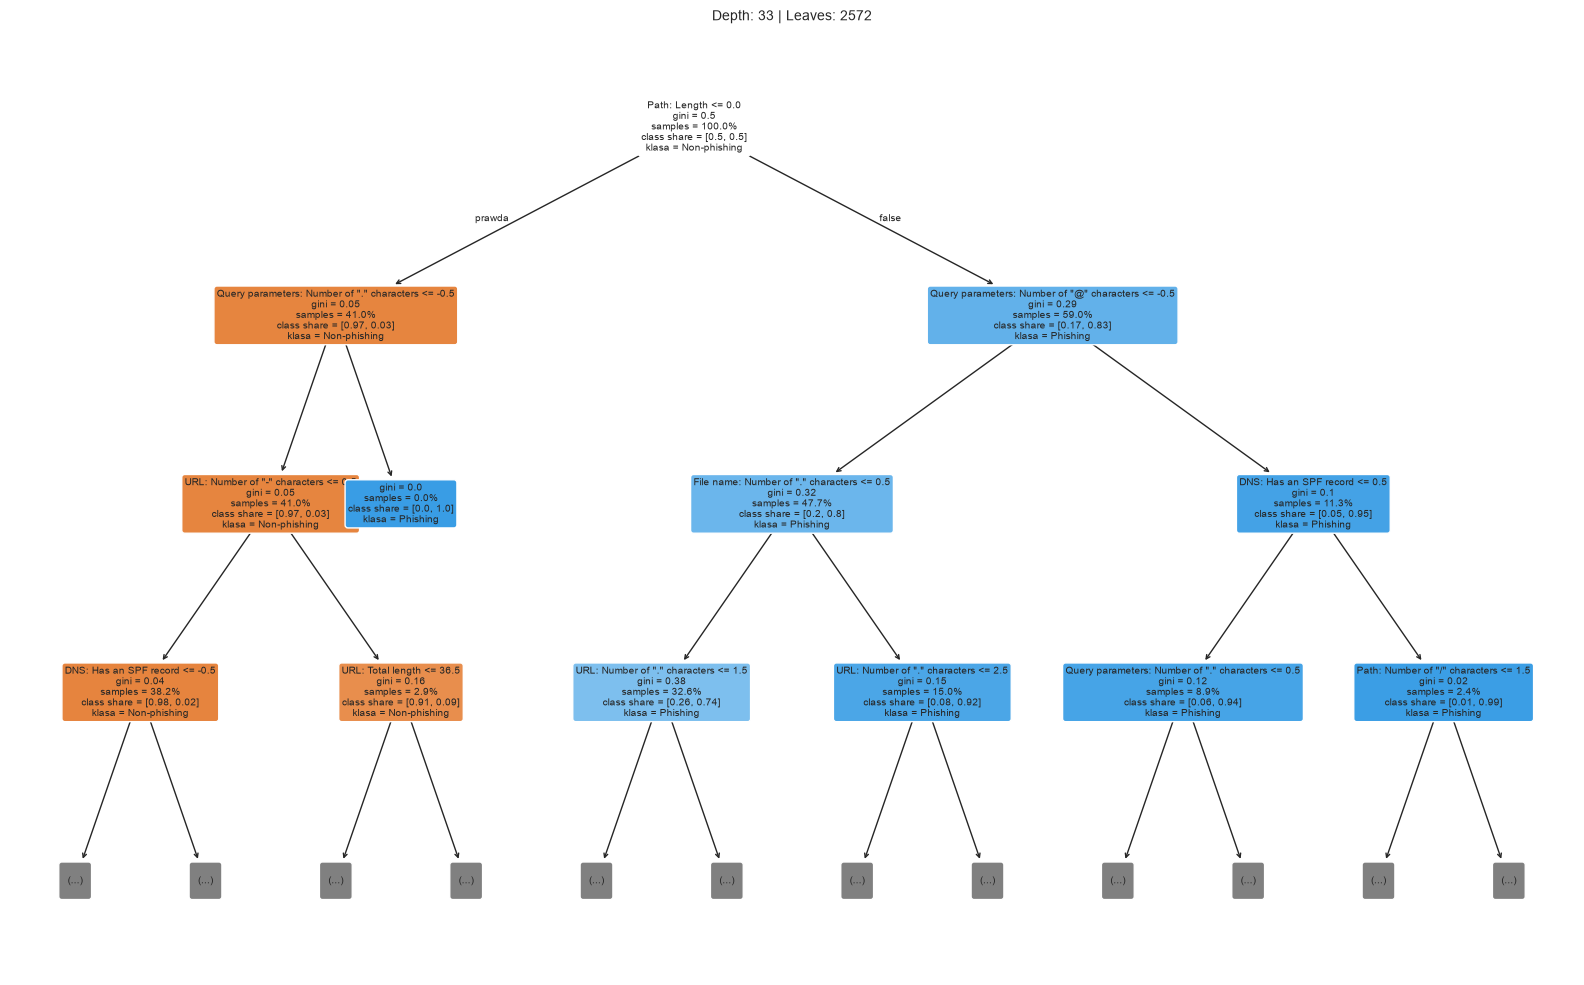

STATYSTYKI DRZEW W LESIE
Pełny zbiór: drzewa=300, średnia głębokość=34.08, średnia liczba liści=2733.60
Zoptymalizowany zbiór: drzewa=300, średnia głębokość=32.97, średnia liczba liści=2618.73


In [11]:
dataset_names = list(trained_models.keys())
for dataset_name in dataset_names:
    model = trained_models[dataset_name]['model']
    X_train = train_test_data[dataset_name]['X_train']
    tree = model.estimators_[0]
    feature_names_readable = [get_readable_name(column) for column in X_train.columns]
    figure, axis = plt.subplots(figsize=(16, 10))
    plot_tree(
        tree, feature_names=feature_names_readable,
        class_names=['Legalny URL', 'Phishing'], filled=True, rounded=True,
        fontsize=7, max_depth=3, ax=axis, proportion=True, precision=2,
        impurity=True,
    )
    for node_label in axis.texts:
        translated = node_label.get_text()
        translated = translated.replace('samples', 'próbki')
        translated = translated.replace('value', 'udział klas')
        translated = translated.replace('class', 'klasa')
        translated = translated.replace('True', 'prawda')
        translated = translated.replace('False', 'fałsz')
        node_label.set_text(translated)
    axis.text(
        0.5, 1.01,
        f'Głębokość: {tree.get_depth()} | Liście: {tree.get_n_leaves()}',
        transform=axis.transAxes, ha='center', va='bottom', fontsize=10,
    )
    figure.tight_layout()
    save_dataset_figure(
        figure, PLOTS_DIR, dataset_name, 'random_forest_tree_visualization.png'
    )
    plt.show()

print("STATYSTYKI DRZEW W LESIE")
for dataset_name in dataset_names:
    model = trained_models[dataset_name]['model']
    tree_depths = [tree.get_depth() for tree in model.estimators_]
    tree_leaves = [tree.get_n_leaves() for tree in model.estimators_]
    print(f"{dataset_name}: drzewa={len(model.estimators_)}, "
          f"średnia głębokość={np.mean(tree_depths):.2f}, "
          f"średnia liczba liści={np.mean(tree_leaves):.2f}")


## 7.1b. Ścieżka decyzyjna dla przykładowego URL


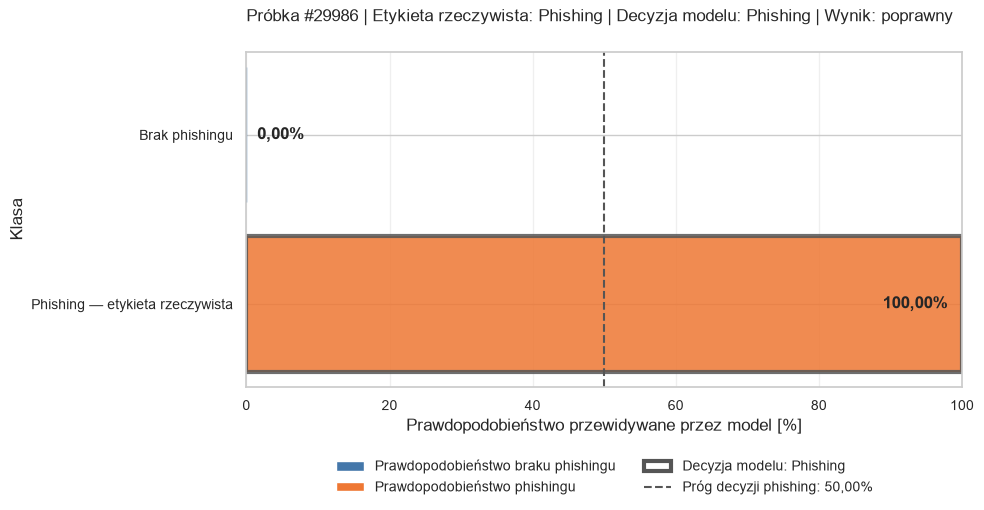

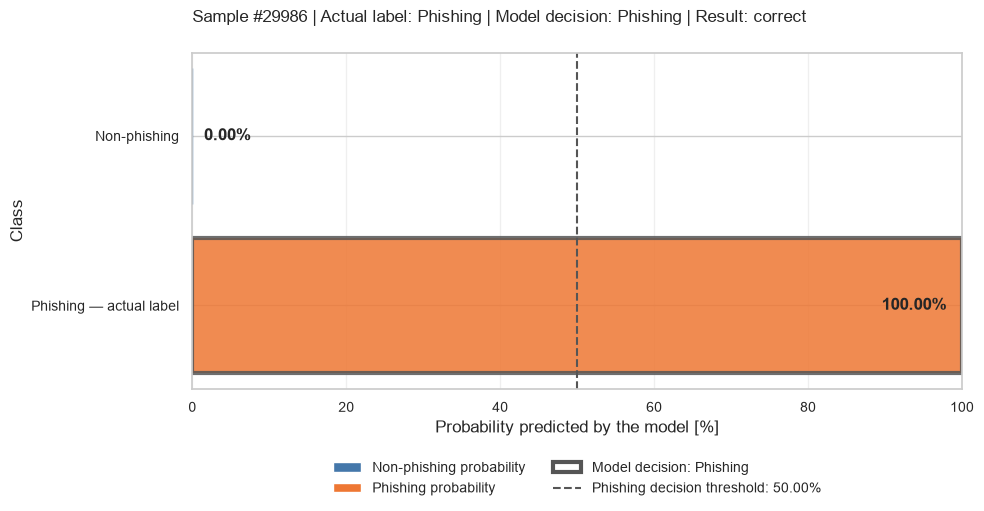

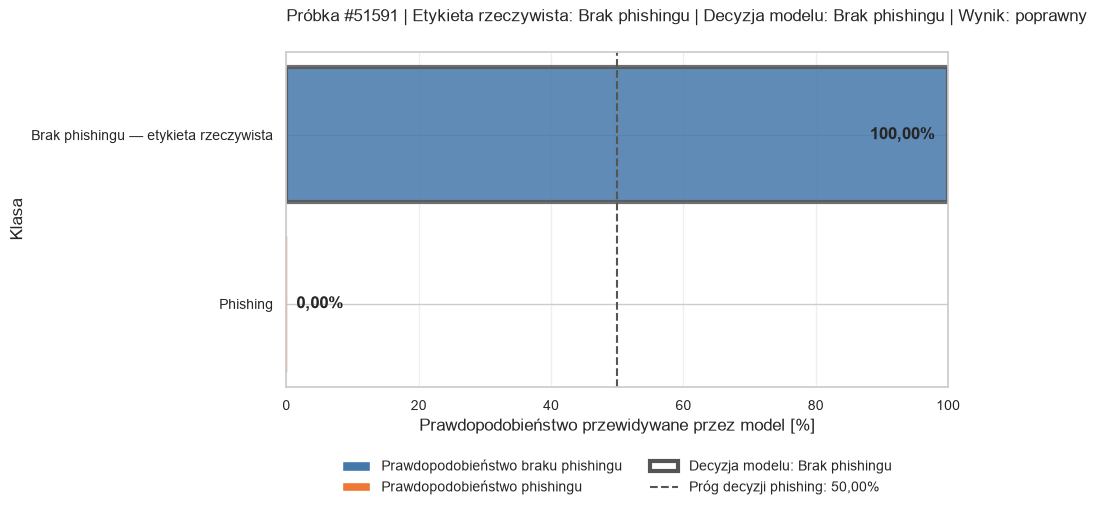

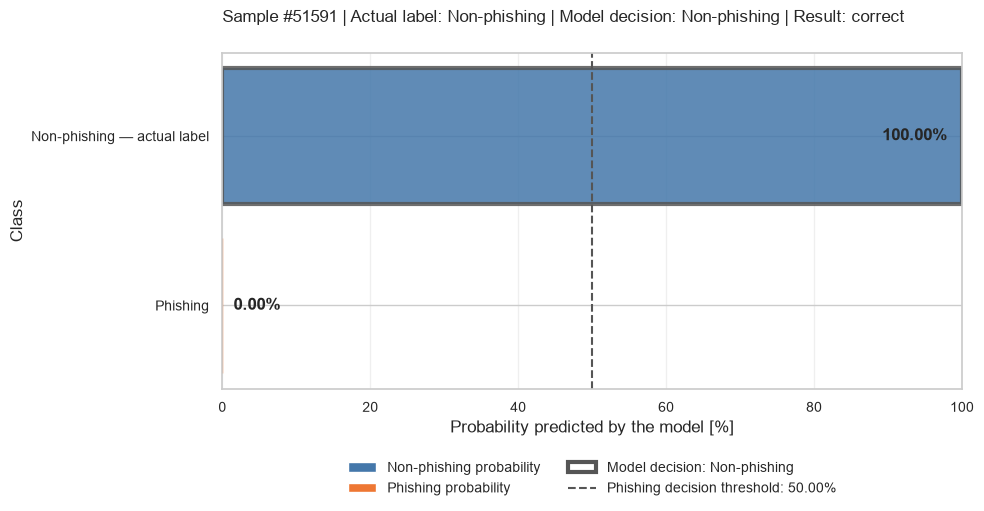

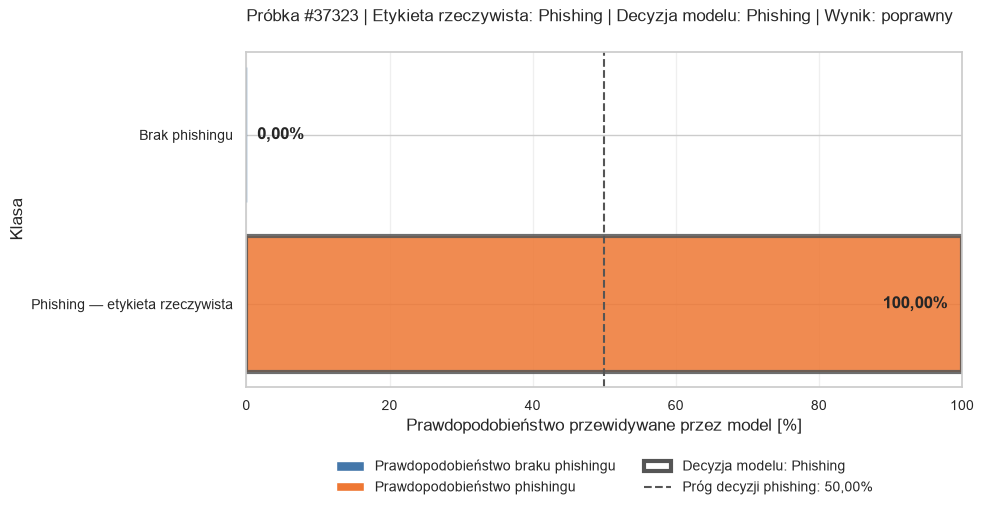

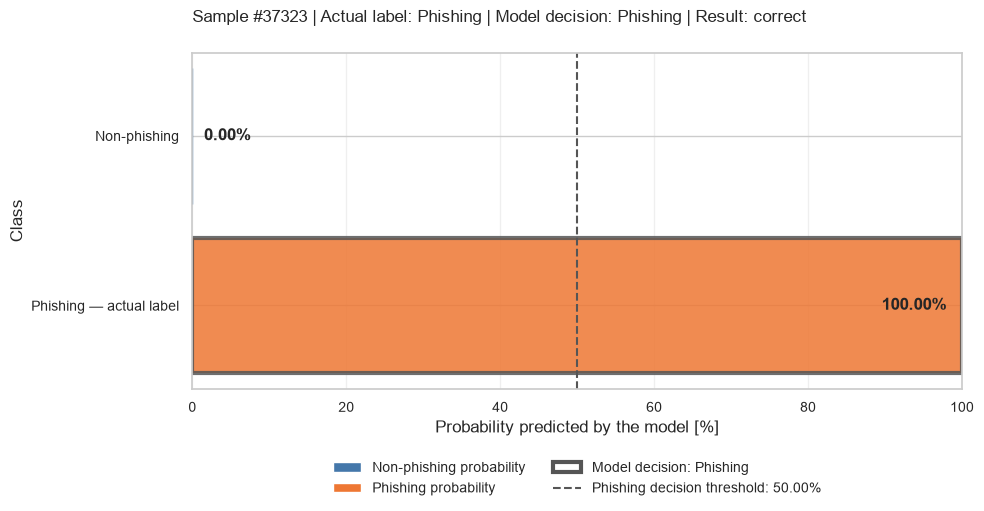

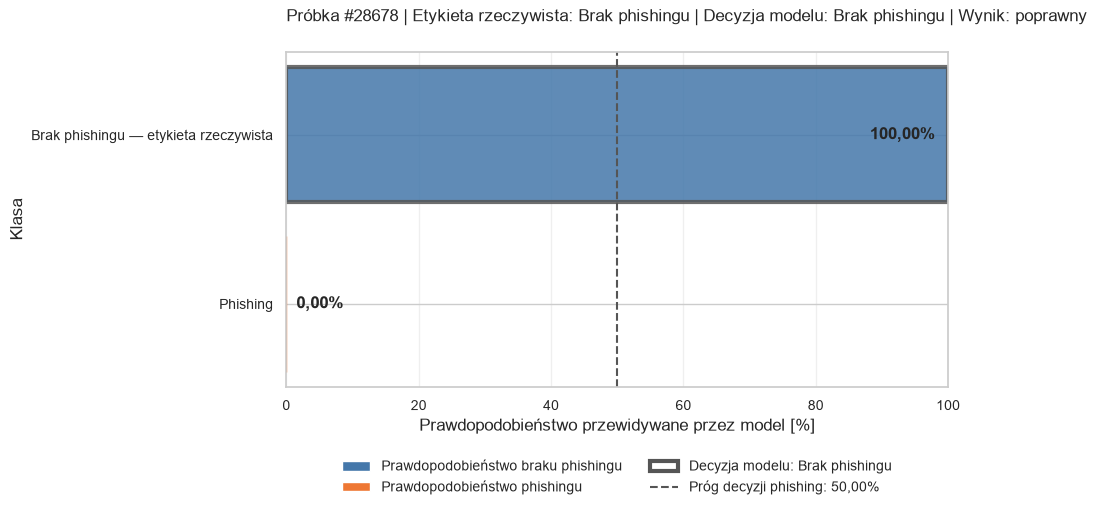

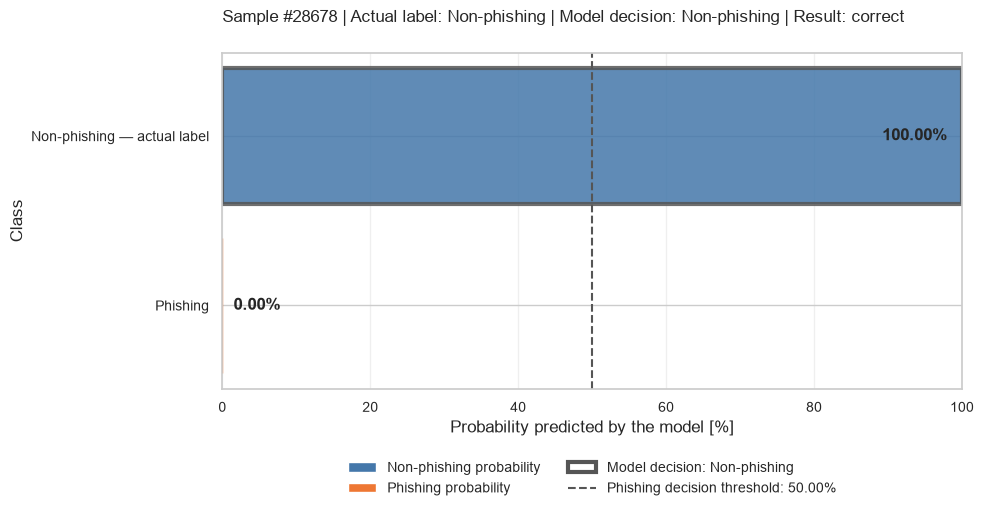

In [12]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    true_labels = train_test_data[dataset_name]['y_test']
    label_values = np.asarray(true_labels, dtype=int)
    probabilities = np.asarray(
        evaluation_results[dataset_name]['y_pred_proba'], dtype=float
    ).reshape(-1)
    threshold = evaluation_results[dataset_name].get('decision_threshold', 0.5)
    sample_positions = {
        'phishing': int(np.flatnonzero(label_values == 1)[0]),
        'bez_phishingu': int(np.flatnonzero(label_values == 0)[0]),
    }
    for sample_kind, position in sample_positions.items():
        sample_id = (
            true_labels.index[position]
            if hasattr(true_labels, 'index') else position
        )
        for language in ['pl', 'en']:
            language_folder = 'pl' if language == 'pl' else 'eng'
            figure, _ = plot_sample_probability_prediction(
                probabilities[position], label_values[position], sample_id,
                decision_threshold=threshold, language=language,
            )
            save_dataset_figure(
                figure, PLOTS_DIR, dataset_name,
                f'{language_folder}/random_forest_sample_prediction_{sample_kind}.png',
            )
            plt.show()
    for obsolete_name in [
        'random_forest_voting_example_phishing.png',
        'random_forest_voting_example_bez_phishingu.png',
        'random_forest_voting_examples.png',
        'random_forest_probability_distribution.png',
        'random_forest_sample_prediction_phishing.png',
        'random_forest_sample_prediction_bez_phishingu.png',
        'random_forest_sample_prediction_phishing_pl.png',
        'random_forest_sample_prediction_phishing_en.png',
        'random_forest_sample_prediction_bez_phishingu_pl.png',
        'random_forest_sample_prediction_bez_phishingu_en.png',
    ]:
        remove_dataset_figure(PLOTS_DIR, dataset_name, obsolete_name)


## 7.2. Krzywe uczenia w pięciokrotnej walidacji krzyżowej

Oś pozioma przedstawia dziesięć rosnących rozmiarów podzbioru uczącego: od
10% do 100% danych dostępnych do uczenia w danym podziale. Dla każdego rozmiaru
model jest dopasowywany w pięciu podziałach. Każdy punkt linii uczenia jest
średnią miary obliczonej na pięciu podzbiorach uczących, a każdy punkt linii
walidacji jest średnią miary obliczonej na pięciu odpowiadających im
podzbiorach walidacyjnych. Pasmo oznacza ± jedno odchylenie standardowe.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.

Walidacja służy do oceny uogólniania modelu podczas jego opracowywania.
Nie jest testem końcowym. Niezależny zbiór testowy nie uczestniczy w
wyznaczaniu tych krzywych; porównanie końcowych wyników uczenia i testowania
znajduje się w sekcji ewaluacji modelu.


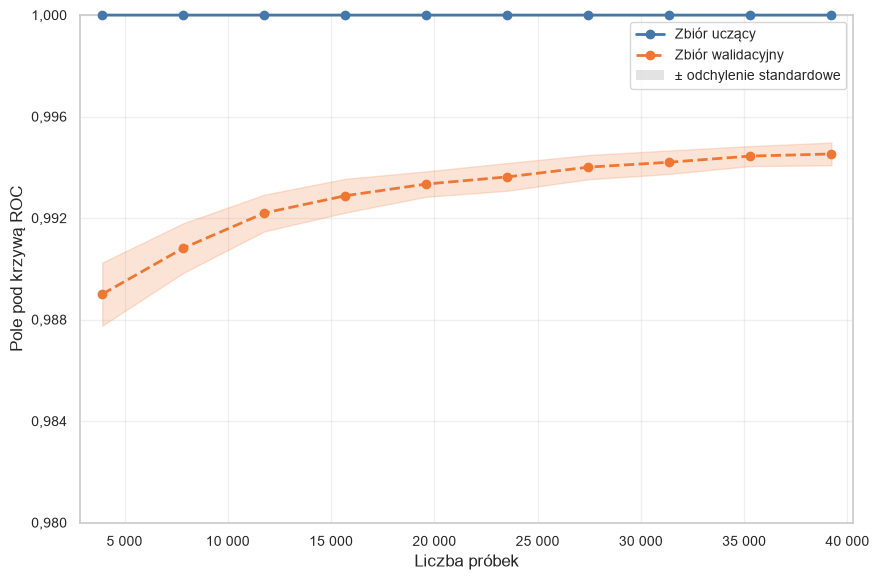

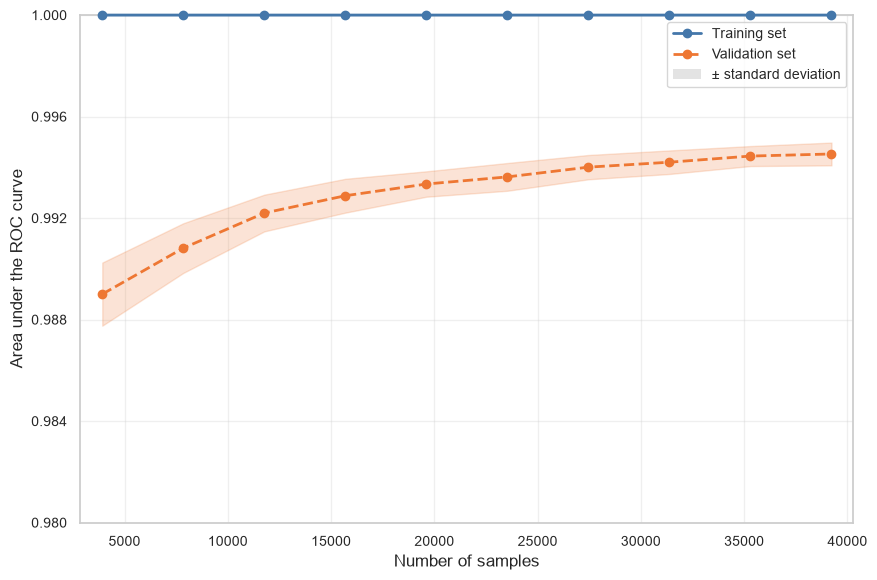

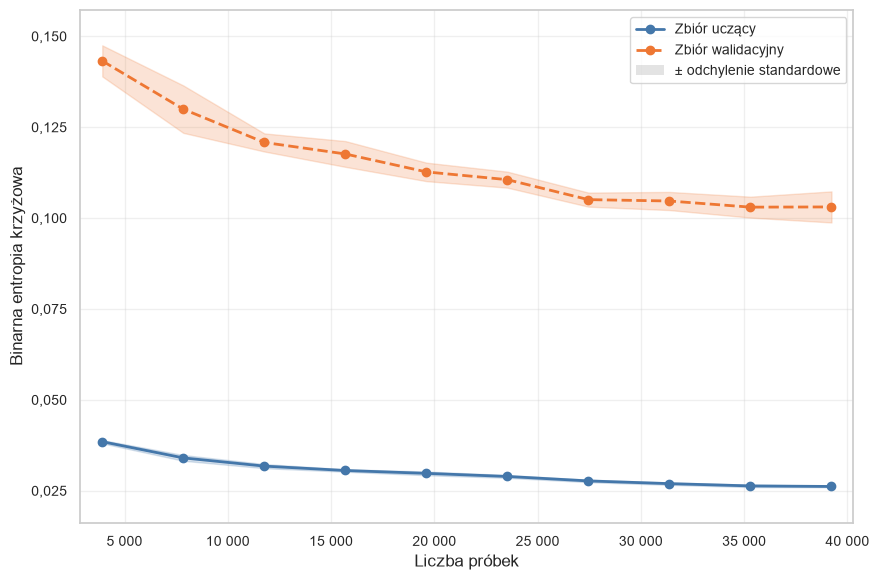

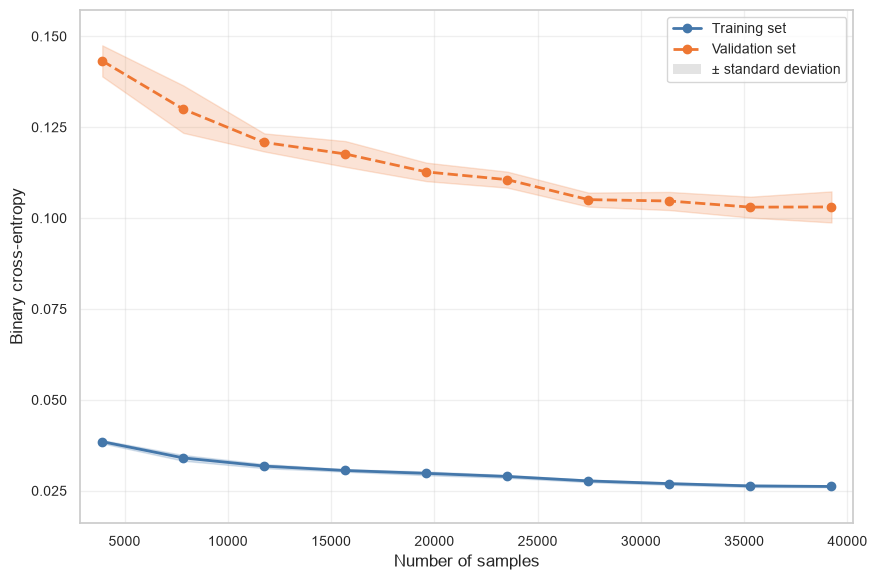

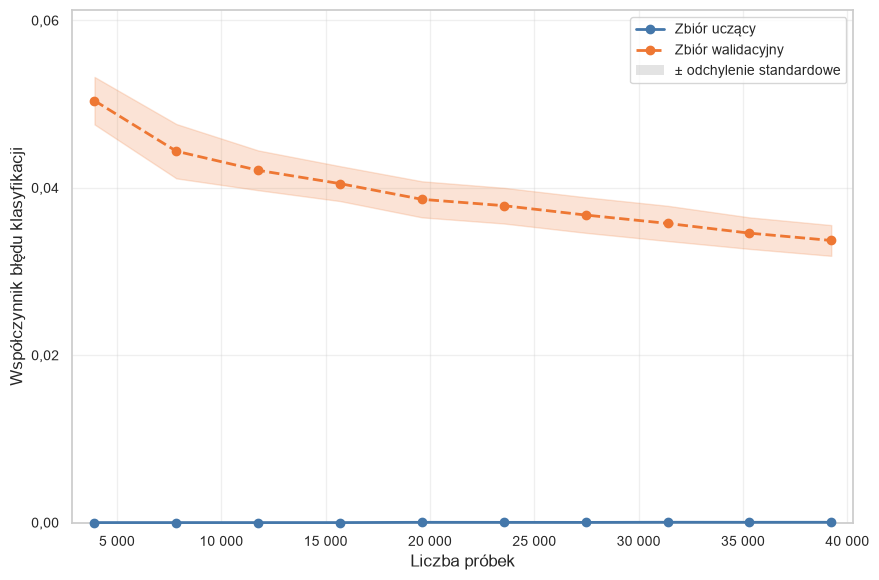

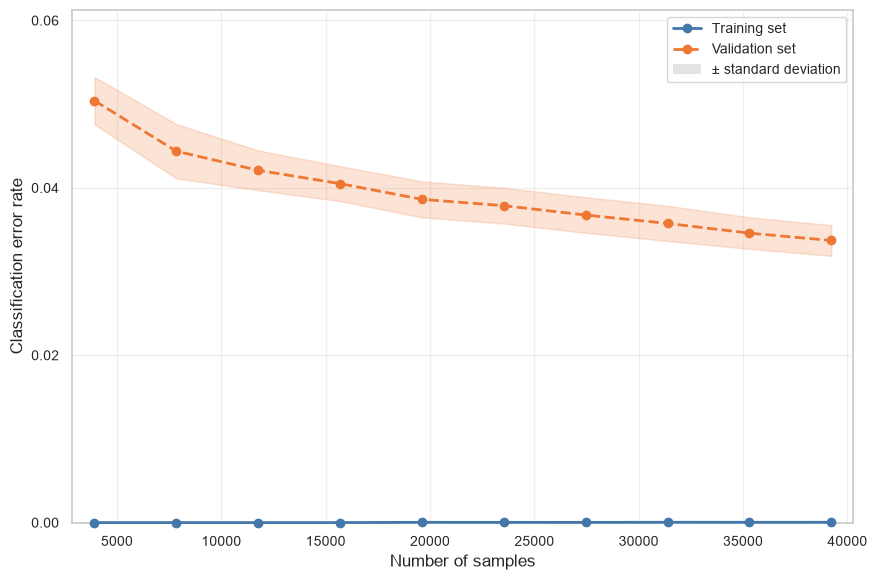

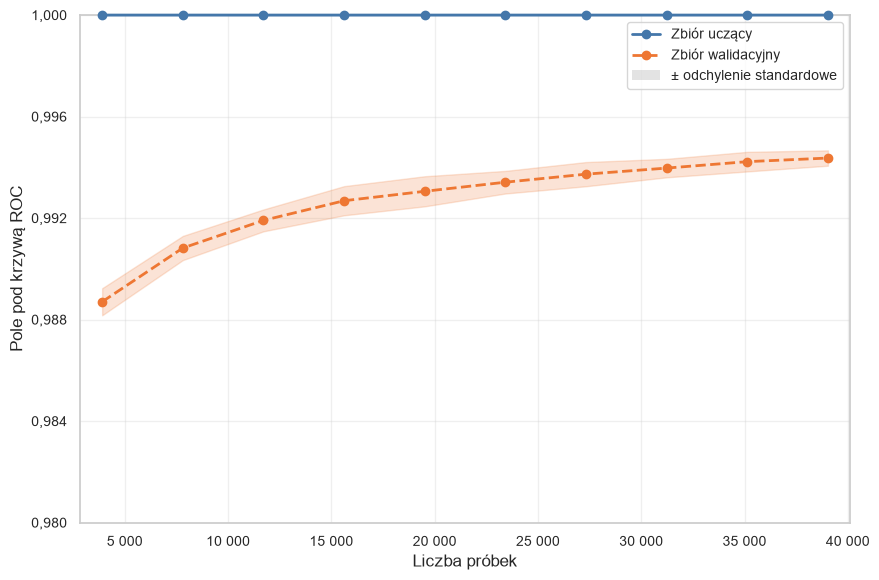

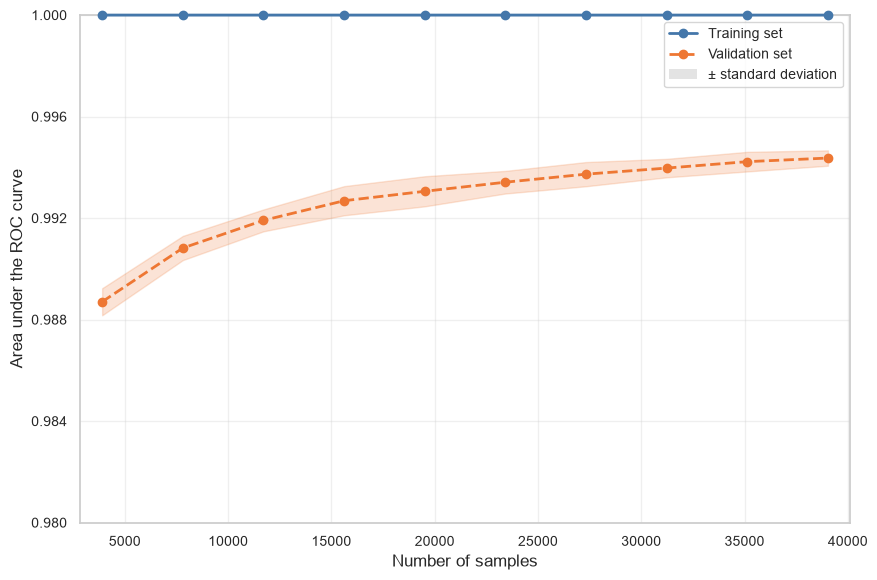

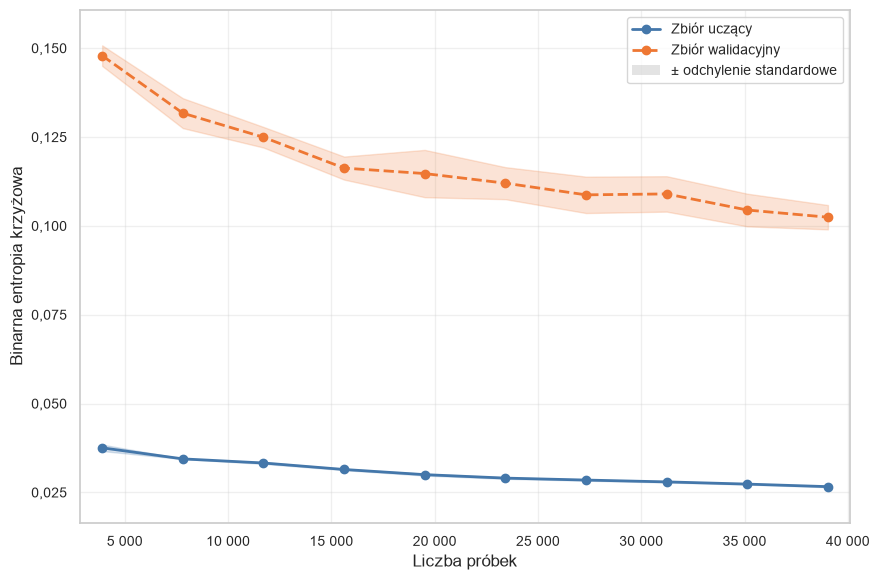

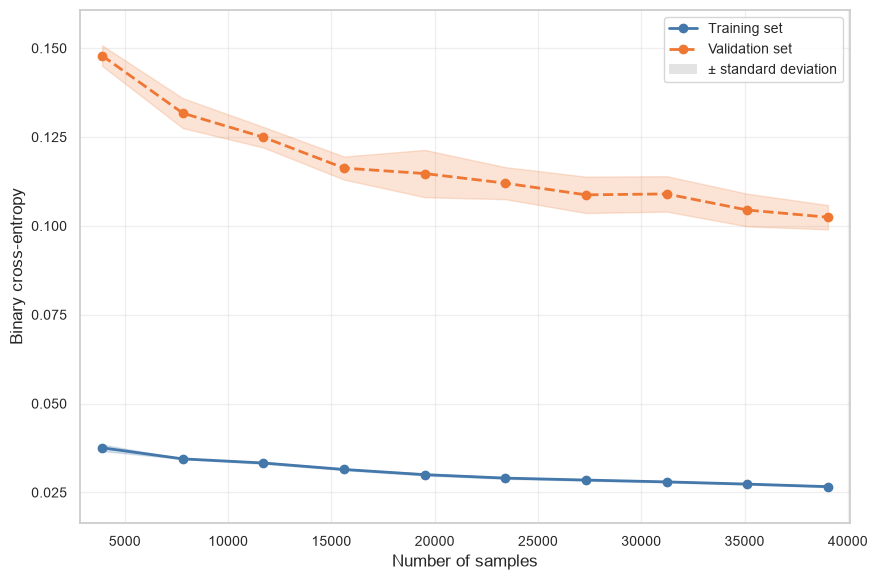

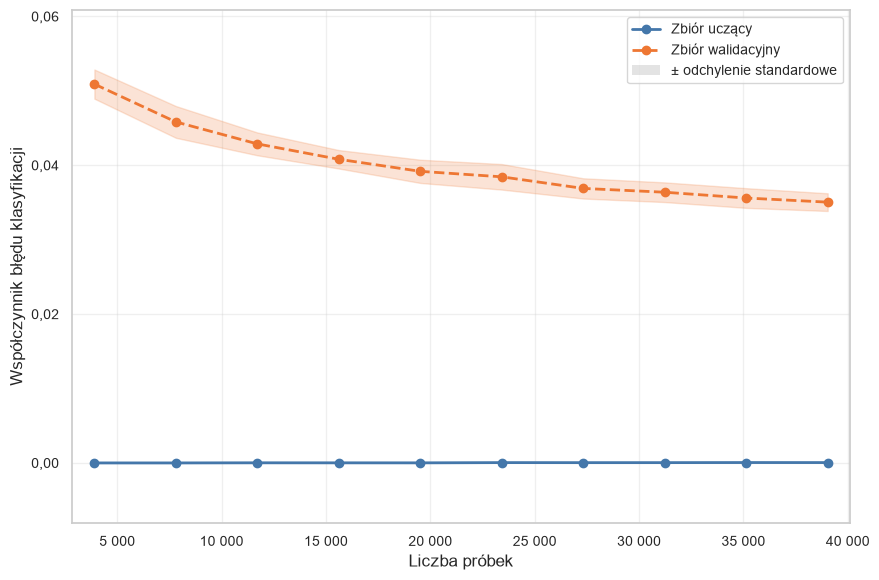

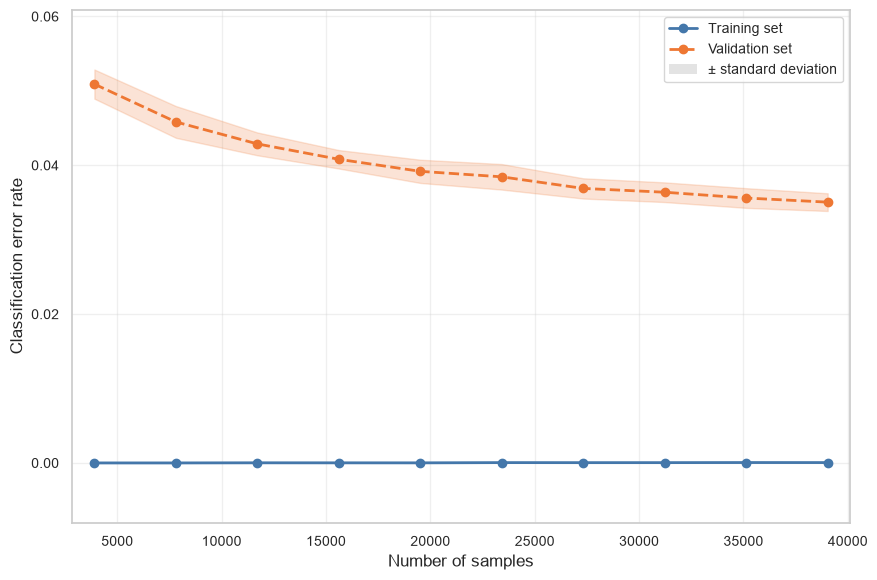

In [13]:
learning_results = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = trained_models[dataset_name]['model']
    X_curve = train_test_data[dataset_name]['X_train']
    y_curve = train_test_data[dataset_name]['y_train']

    train_sizes, train_scores, validation_scores = learning_curve(
        model, train_test_data[dataset_name]['X_train'], train_test_data[dataset_name]['y_train'], cv=5, scoring='roc_auc', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    _, train_log_loss, validation_log_loss = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='neg_log_loss', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    _, train_accuracy, validation_accuracy = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='accuracy', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    learning_results[dataset_name] = {
        'x': train_sizes,
        'train_mean': train_scores.mean(axis=1),
        'train_std': train_scores.std(axis=1),
        'validation_mean': validation_scores.mean(axis=1),
        'validation_std': validation_scores.std(axis=1),
        'train_log_loss_mean': (-train_log_loss).mean(axis=1),
        'train_log_loss_std': (-train_log_loss).std(axis=1),
        'validation_log_loss_mean': (-validation_log_loss).mean(axis=1),
        'validation_log_loss_std': (-validation_log_loss).std(axis=1),
        'train_error_rate_mean': (1.0 - train_accuracy).mean(axis=1),
        'train_error_rate_std': train_accuracy.std(axis=1),
        'validation_error_rate_mean': (1.0 - validation_accuracy).mean(axis=1),
        'validation_error_rate_std': validation_accuracy.std(axis=1),
    }

for dataset_name, values in learning_results.items():
    figure, _ = plot_score_curve(
        values['x'], values['train_mean'], values['train_std'],
        values['validation_mean'], values['validation_std'],
        x_label='Liczba próbek',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_learning_curves.png')
    plt.show()

    figure, _ = plot_score_curve(
        values['x'], values['train_log_loss_mean'], values['train_log_loss_std'],
        values['validation_log_loss_mean'], values['validation_log_loss_std'],
        x_label='Liczba próbek',
        y_label='Binarna entropia krzyżowa',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_bce_learning_curves.png')
    plt.show()

    figure, _ = plot_score_curve(
        values['x'], values['train_error_rate_mean'], values['train_error_rate_std'],
        values['validation_error_rate_mean'], values['validation_error_rate_std'],
        x_label='Liczba próbek',
        y_label='Współczynnik błędu klasyfikacji',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_error_rate_learning_curves.png')
    plt.show()


## 7.3. Wpływ liczby drzew (n_estimators) na skuteczność modelu


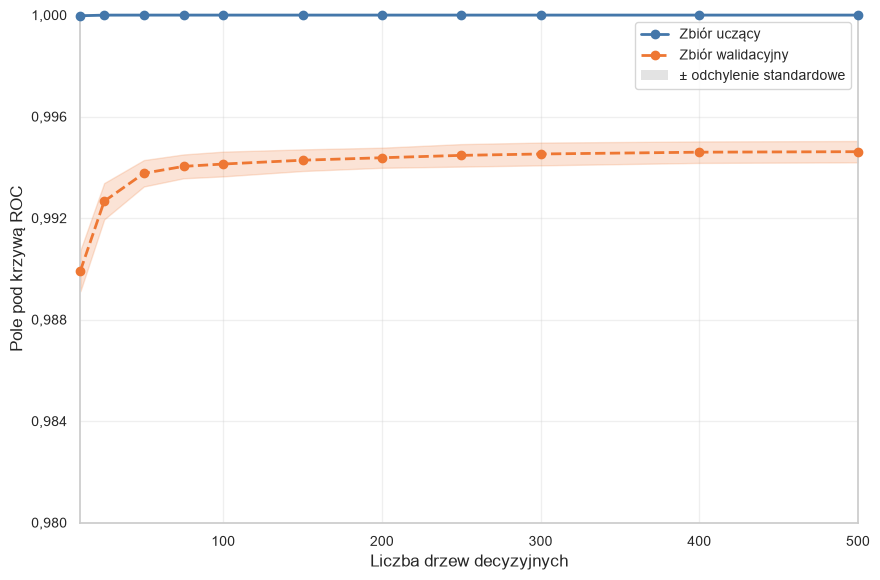

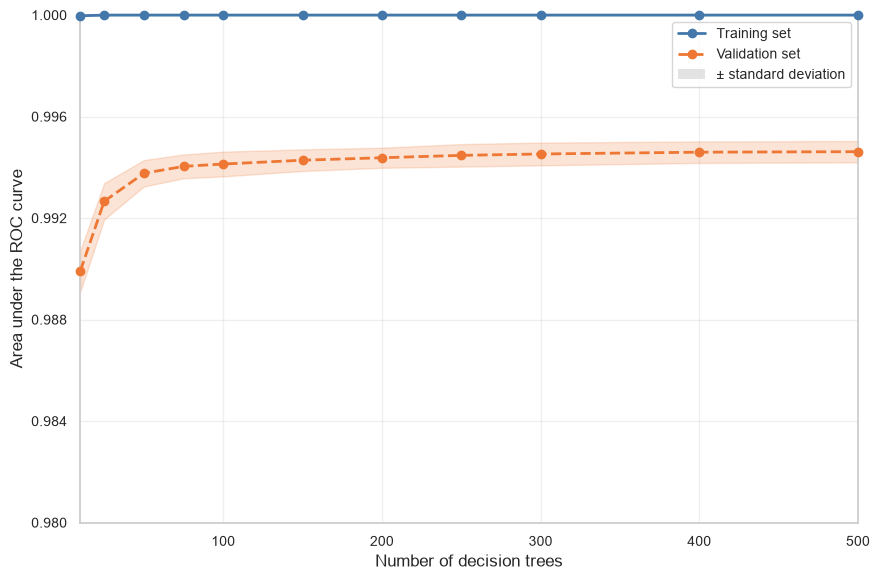

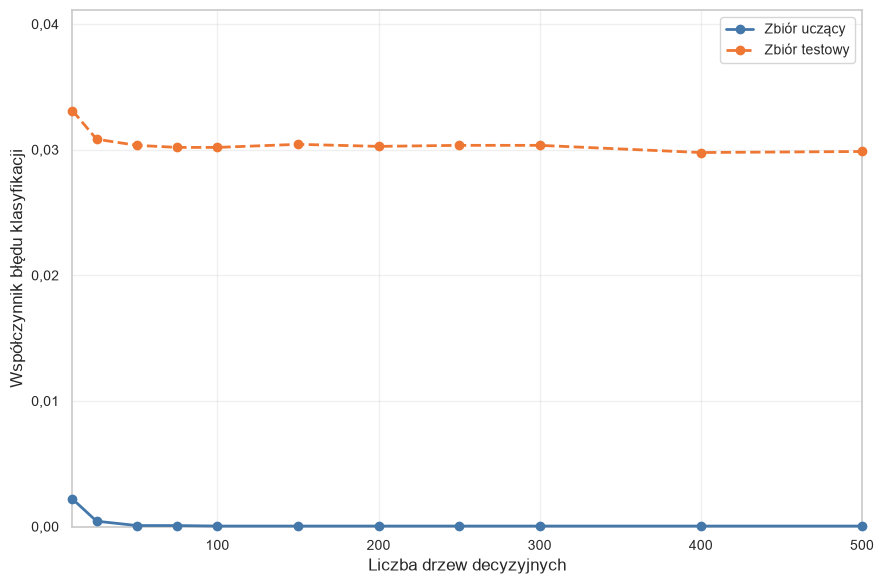

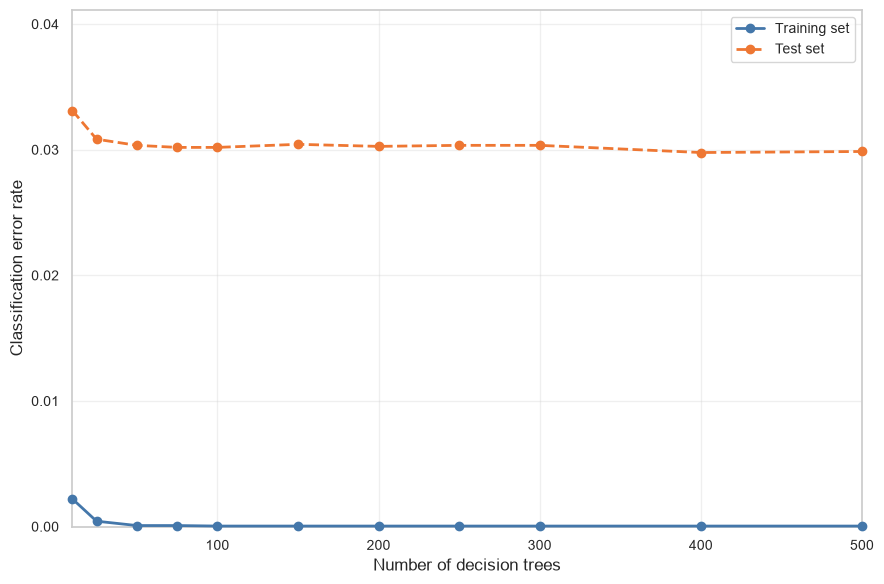

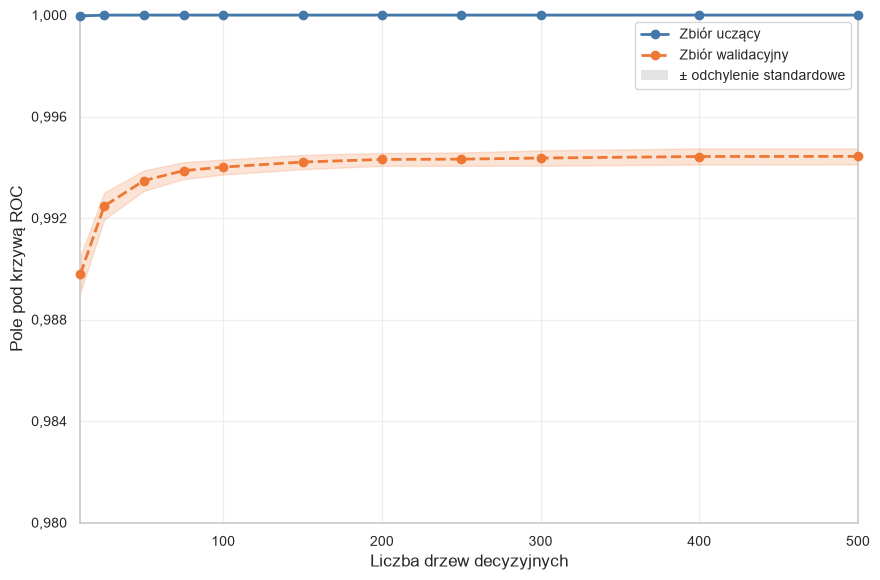

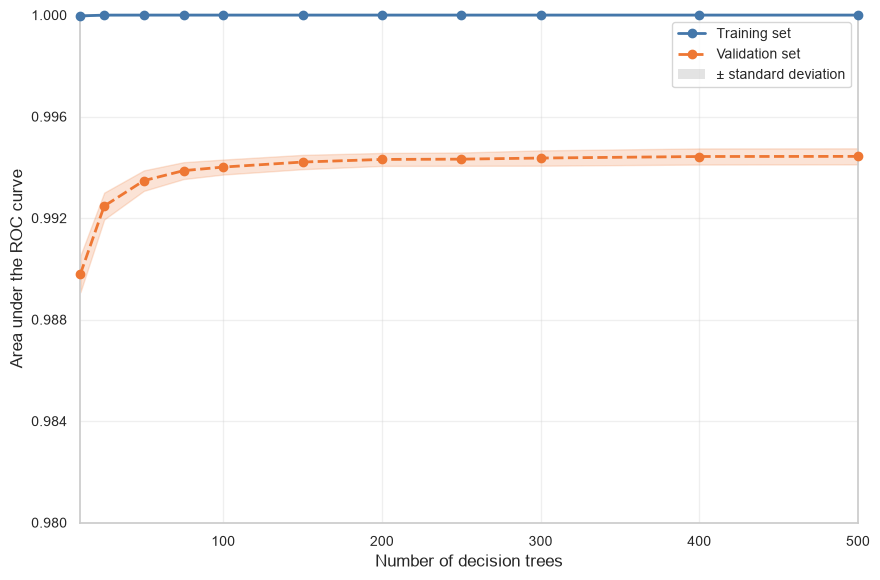

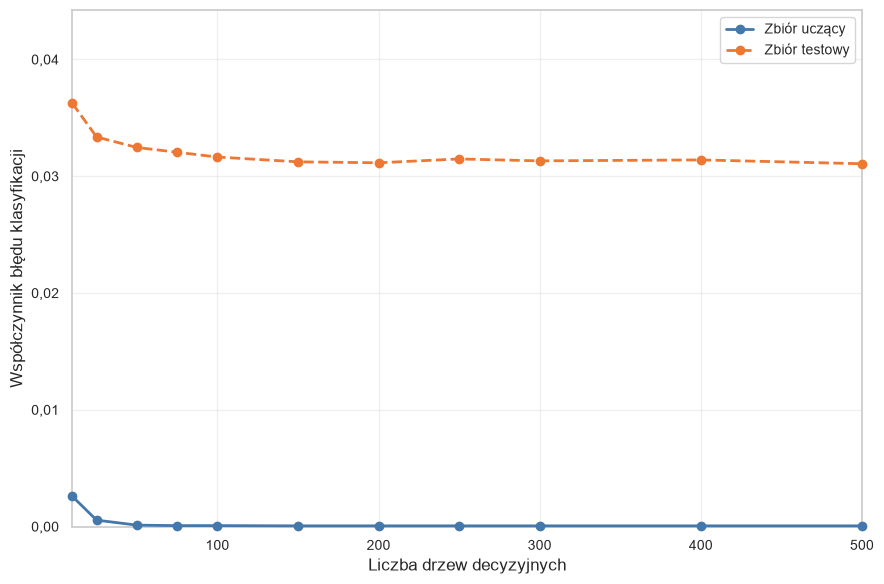

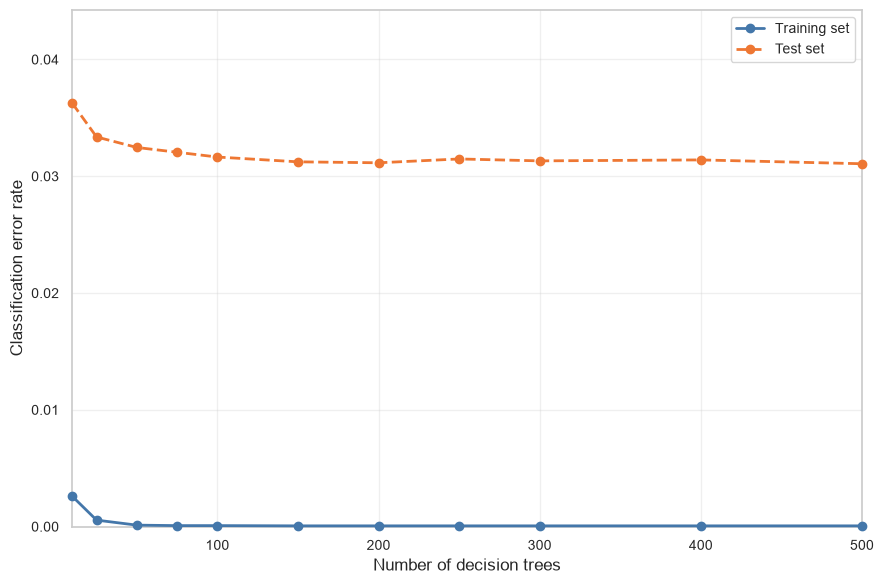

In [14]:
validation_results = {}
param_range = np.array([10, 25, 50, 75, 100, 150, 200, 250, 300, 400, 500])
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    X_curve = train_test_data[dataset_name]['X_train']
    y_curve = train_test_data[dataset_name]['y_train']
    X_test_curve = train_test_data[dataset_name]['X_test']
    y_test_curve = train_test_data[dataset_name]['y_test']

    model_base = RandomForestClassifier(random_state=42, n_jobs=-1)
    train_scores, validation_scores = validation_curve(
        model_base, X_curve, y_curve, param_name='n_estimators', param_range=param_range,
        cv=5, scoring='roc_auc', n_jobs=-1,
    )
    validation_results[dataset_name] = {
        'train_mean': train_scores.mean(axis=1),
        'train_std': train_scores.std(axis=1),
        'validation_mean': validation_scores.mean(axis=1),
        'validation_std': validation_scores.std(axis=1),
        'train_errors': [],
        'test_errors': [],
    }
    for parameter_value in param_range:
        parameter_model = RandomForestClassifier(
            n_estimators=int(parameter_value), random_state=42, n_jobs=-1
        )
        parameter_model.fit(X_curve, y_curve)
        validation_results[dataset_name]['train_errors'].append(
            1.0 - accuracy_score(y_curve, parameter_model.predict(X_curve))
        )
        validation_results[dataset_name]['test_errors'].append(
            1.0 - accuracy_score(y_test_curve, parameter_model.predict(X_test_curve))
        )

for dataset_name, values in validation_results.items():
    figure, _ = plot_score_curve(
        param_range, values['train_mean'], values['train_std'],
        values['validation_mean'], values['validation_std'],
        x_label='Liczba drzew decyzyjnych', logarithmic_x=False,
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_validation_curves.png')
    plt.show()
    figure, _ = plot_parameter_train_test_error(
        param_range, values['train_errors'], values['test_errors'],
        x_label='Liczba drzew decyzyjnych', logarithmic_x=False,
    )
    remove_dataset_figure(PLOTS_DIR, dataset_name, 'random_forest_parameter_train_validation_error.png')
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_parameter_train_test_error.png')
    plt.show()


## 7.4. Tabela porównawcza wyników


In [15]:
comparison_df = pd.DataFrame({
    'Zbiór danych': ['Pełny zbiór', 'Zoptymalizowany zbiór'],
    'Dokładność': [evaluation_results['Pełny zbiór']['accuracy'], evaluation_results['Zoptymalizowany zbiór']['accuracy']],
    'Precyzja': [evaluation_results['Pełny zbiór']['precision'], evaluation_results['Zoptymalizowany zbiór']['precision']],
    'Czułość': [evaluation_results['Pełny zbiór']['recall'], evaluation_results['Zoptymalizowany zbiór']['recall']],
    'Miara F1': [evaluation_results['Pełny zbiór']['f1'], evaluation_results['Zoptymalizowany zbiór']['f1']],
    'AUC-ROC': [evaluation_results['Pełny zbiór']['auc_roc'], evaluation_results['Zoptymalizowany zbiór']['auc_roc']],
    'Średnia CV AUC': [evaluation_results['Pełny zbiór']['cv_mean'], evaluation_results['Zoptymalizowany zbiór']['cv_mean']],
    'Odchylenie CV AUC': [evaluation_results['Pełny zbiór']['cv_std'], evaluation_results['Zoptymalizowany zbiór']['cv_std']],
    'Czas uczenia (s)': [trained_models['Pełny zbiór']['training_time'], trained_models['Zoptymalizowany zbiór']['training_time']],
    'Liczba cech': [data_splits['Pełny zbiór']['feature_count'], data_splits['Zoptymalizowany zbiór']['feature_count']],
    'Średnie CPU [%]': [resource_stats[name]['stats']['cpu']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalne CPU [%]': [resource_stats[name]['stats']['cpu']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Średni RAM [GB]': [resource_stats[name]['stats']['ram']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalny RAM [GB]': [resource_stats[name]['stats']['ram']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Próbki pomiarowe': [resource_stats[name]['stats']['samples'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']]
})

comparison_path = backend_root.parent / 'results' / 'original' / 'model_comparisons' / 'random_forest_comparison.csv'
comparison_path.parent.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(comparison_path, index=False)
print(f"✓ Porównanie zapisane: {comparison_path}")
print("\nTabela porównawcza:")
print(comparison_df.to_string(index=False))

✓ Porównanie zapisane: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/model_comparisons/random_forest_comparison.csv

Tabela porównawcza:
         Zbiór danych  Dokładność  Precyzja  Czułość  Miara F1  AUC-ROC  Średnia CV AUC  Odchylenie CV AUC  Czas uczenia (s)  Liczba cech  Średnie CPU [%]  Maksymalne CPU [%]  Średni RAM [GB]  Maksymalny RAM [GB]  Próbki pomiarowe
          Pełny zbiór    0.969655  0.964799 0.974874  0.969810 0.995169        0.994525           0.000449          1.528341          111        81.334956          102.189468         0.393849             0.473022                24
Zoptymalizowany zbiór    0.968686  0.965478 0.972127  0.968791 0.994599        0.994365           0.000302          1.455125           74        86.104597          105.207401         0.360975             0.437302                23


## 7.5. Ważność cech w obu modelach


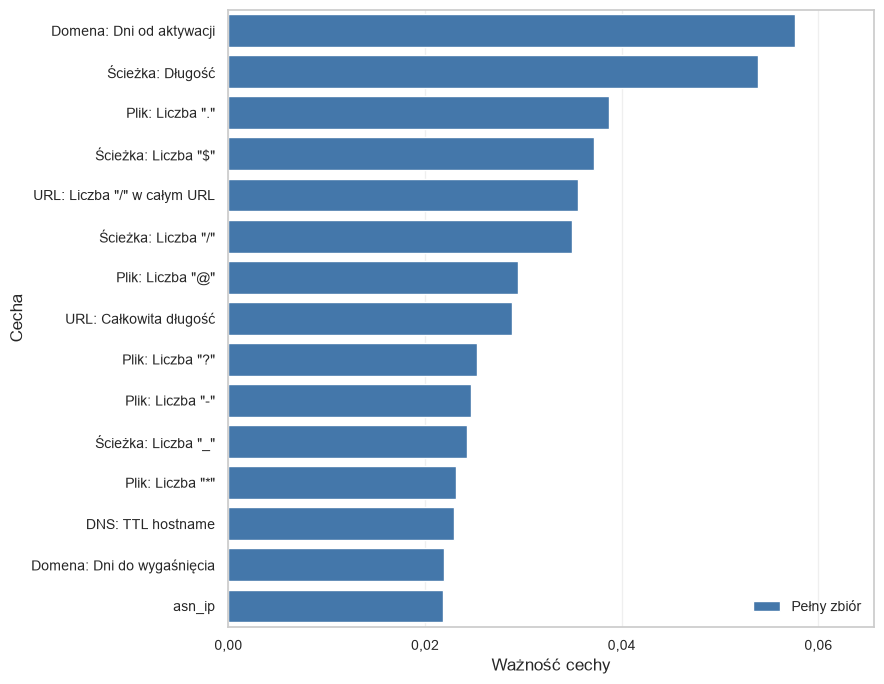

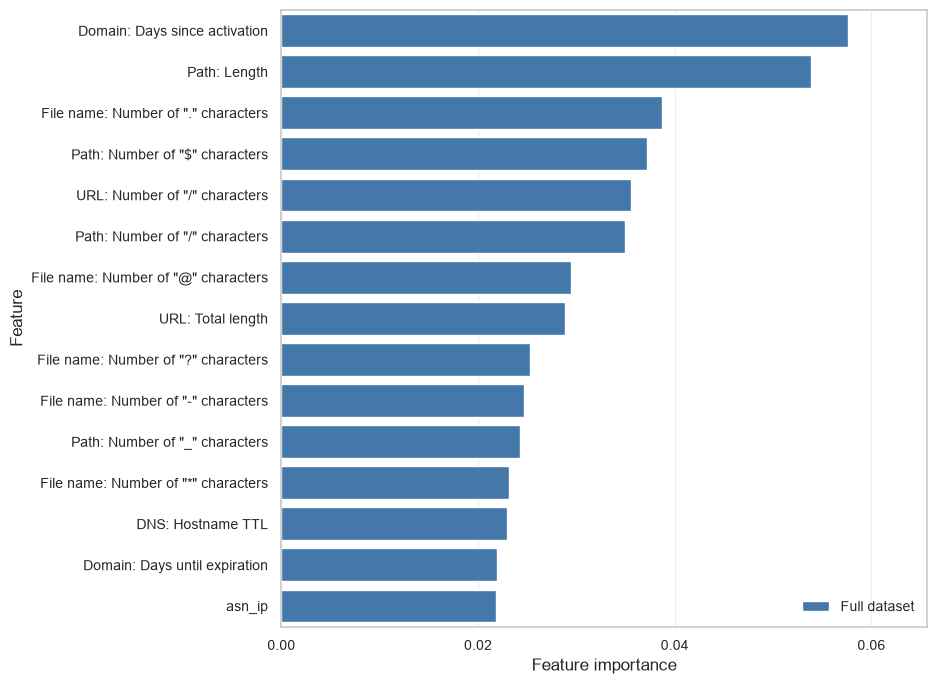

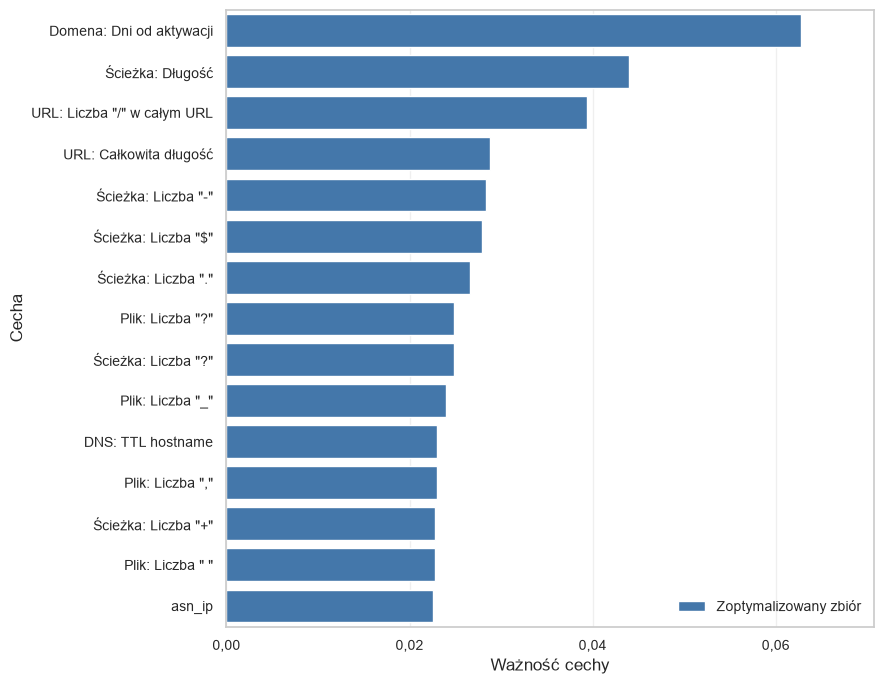

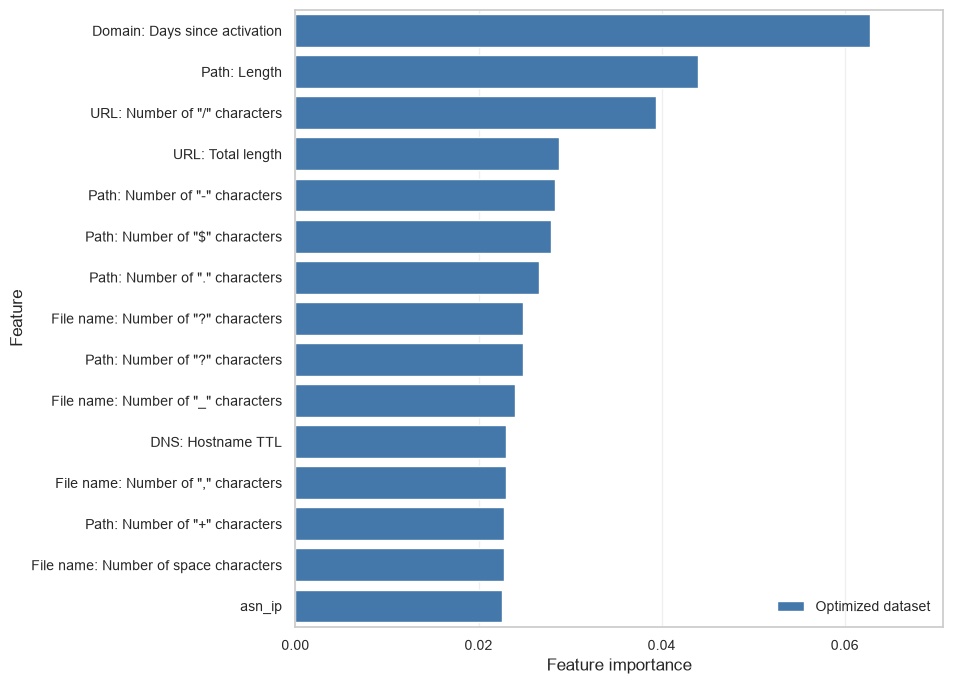

In [16]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = trained_models[dataset_name]['model']
    X_features = train_test_data[dataset_name]['X_train']
    feature_importance = pd.DataFrame({
        'Cecha': [get_readable_name(column) for column in X_features.columns],
        'Ważność': model.feature_importances_,
    }).sort_values('Ważność', ascending=False).head(15)
    figure, _ = plot_feature_ranking(
        feature_importance, dataset_name, x_column='Ważność', x_label='Ważność cechy'
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_feature_importance.png')
    plt.show()


## 8. Zapis modelu


In [17]:
for dataset_name, model_data in trained_models.items():
    model = model_data['model']

    if 'Pełny' in dataset_name:
        model_filename = f'{MODELS_DIR}/random_forest_full.pkl'
    else:
        model_filename = f'{MODELS_DIR}/random_forest_optimized.pkl'

    model_save_data = {
        'model': model,
        'scaler': None,
        'feature_names': train_test_data[dataset_name]['X_train'].columns.tolist(),
        'best_params': model_data['params'],
        'metrics': {
            'accuracy': evaluation_results[dataset_name]['accuracy'],
            'precision': evaluation_results[dataset_name]['precision'],
            'recall': evaluation_results[dataset_name]['recall'],
            'f1': evaluation_results[dataset_name]['f1'],
            'auc_roc': evaluation_results[dataset_name]['auc_roc'],
            'cv_auc_mean': evaluation_results[dataset_name]['cv_mean'],
            'cv_auc_std': evaluation_results[dataset_name]['cv_std']
        }
    }

    with open(model_filename, 'wb') as f:
        pickle.dump(model_save_data, f)

    print(f"✅ {dataset_name}:")
    print(f"   Model zapisany: {model_filename}")
    print(f"   Parametry: {model_data['params']}")
    print(f"   CV ROC-AUC: {model_data['cv_score']:.4f}")
    print(f"   Test ROC-AUC: {evaluation_results[dataset_name]['auc_roc']:.4f}")
    print()

print("="*80)
print("PODSUMOWANIE KOŃCOWE")
print("="*80)
print(f"\nPrzeszkolono i zapisano {len(trained_models)} modele Random Forest:")
print(f"  1. Model na pełnym zbiorze: {data_splits['Pełny zbiór']['feature_count']} cech")
print(f"  2. Model na zoptymalizowanym zbiorze: {data_splits['Zoptymalizowany zbiór']['feature_count']} cech")
print(f"\nWizualizacje zapisane w: {PLOTS_DIR}/")
print(f"Modele zapisane w: {MODELS_DIR}/")


✅ Pełny zbiór:
   Model zapisany: ../models/random_forest/random_forest_full.pkl
   Parametry: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
   CV ROC-AUC: 0.9945
   Test ROC-AUC: 0.9952

✅ Zoptymalizowany zbiór:
   Model zapisany: ../models/random_forest/random_forest_optimized.pkl
   Parametry: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
   CV ROC-AUC: 0.9944
   Test ROC-AUC: 0.9946

PODSUMOWANIE KOŃCOWE

Przeszkolono i zapisano 2 modele Random Forest:
  1. Model na pełnym zbiorze: 111 cech
  2. Model na zoptymalizowanym zbiorze: 74 cech

Wizualizacje zapisane w: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/original/plots/random_forest/
Modele zapisane w: ../models/random_forest/
